#BASE DE DATOS SELECCIONADA: Financial Statement analysis
Obtenida de Kaggle: https://www.kaggle.com/competitions/home-credit-default-risk/data

##Importo la base de datos Home Default Risk Credit

In [65]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

path = '/content/drive/MyDrive/00 MAESTRIA/Primera Entrega: Método de Conglomerados/application_train.csv'
df = pd.read_csv(path)
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## 1. Análisis exploratorio: dimensiones y estructura de la base

Análisis exploratorio (variables, descriptivos, correlaciones y faltantes).

### 1.1. Análisis inicial

In [66]:
# 1. Dimensiones de la base
print("Cantidad de observaciones:", df.shape[0])   # Indica la cantidad de observaciones (solicitudes de crédito).
print("Cantidad de variables:", df.shape[1])       # Indica la cantidad de variables disponibles.

# 2. Estructura y tipos de datos
df.info()                                          # Muestra el nombre, tipo de dato y cantidad de valores no nulos de cada variable.
                                                   # una variable como int64 o float64 no significa necesariamente que sea métrica. Algunas variables numéricas representan categorías o identificadores.

# 3. Visualizar las primeras 5 observaciones
display(df.head())

Cantidad de observaciones: 307511
Cantidad de variables: 122
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


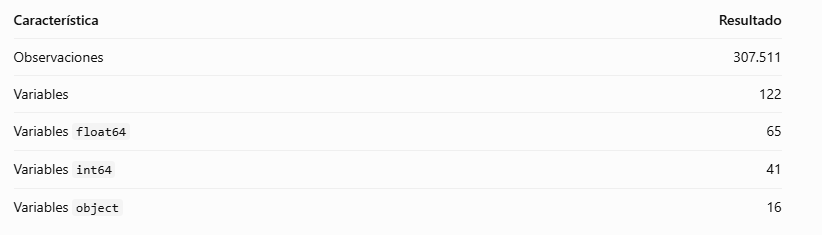

Tenemos una base suficientemente grande para aplicar análisis de clústeres. Además, hay muchas variables numéricas candidatas, aunque todavía debemos distinguir las métricas de los identificadores y las variables categóricas codificadas con números.

### 1.2. Identificación de variables métricas y no métricas

In [67]:
# Identificación de tipos de variables

resumen_variables = pd.DataFrame({
    'Variable': df.columns,
    'Tipo_Python': df.dtypes.astype(str).values,
    'Valores_unicos': df.nunique().values
})

# Mostrar todas las variables
display(resumen_variables)

,Variable,Tipo_Python,Valores_unicos
0,SK_ID_CURR,int64,307511
1,TARGET,int64,2
2,NAME_CONTRACT_TYPE,object,2
3,CODE_GENDER,object,3
4,FLAG_OWN_CAR,object,2
...,...,...,...
117,AMT_REQ_CREDIT_BUREAU_DAY,float64,9
118,AMT_REQ_CREDIT_BUREAU_WEEK,float64,9
119,AMT_REQ_CREDIT_BUREAU_MON,float64,24
120,AMT_REQ_CREDIT_BUREAU_QRT,float64,11


Nuestro objetivo es identificar perfiles de solicitantes de crédito según sus características económicas, financieras y crediticias.
Elegimos las variables métricas que vamos a usar.

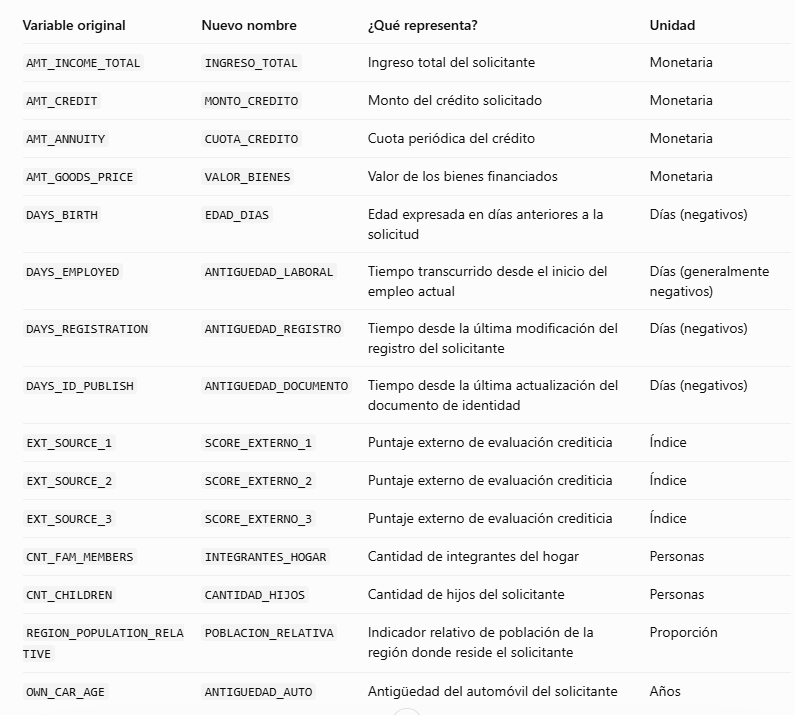

Todas son cuantitativas, aunque algunas son discretas y otras continuas.
Esta es una selcción preliminar, no sabemos si todas nos van a servir, para eso continuamos analizandolas.

### 1.3. Selección inicial y renombramiento de las 15 variables métricas

In [68]:
# Selección inicial de 15 variables métricas

variables_candidatas = [
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'AMT_GOODS_PRICE',
    'DAYS_BIRTH',
    'DAYS_EMPLOYED',
    'DAYS_REGISTRATION',
    'DAYS_ID_PUBLISH',
    'EXT_SOURCE_1',
    'EXT_SOURCE_2',
    'EXT_SOURCE_3',
    'CNT_FAM_MEMBERS',
    'CNT_CHILDREN',
    'REGION_POPULATION_RELATIVE',
    'OWN_CAR_AGE'
]

# Diccionario para renombrar las variables en español y mayúsculas
nombres_variables = {
    'AMT_INCOME_TOTAL': 'INGRESO_TOTAL',
    'AMT_CREDIT': 'MONTO_CREDITO',
    'AMT_ANNUITY': 'CUOTA_CREDITO',
    'AMT_GOODS_PRICE': 'VALOR_BIENES',
    'DAYS_BIRTH': 'EDAD_DIAS',
    'DAYS_EMPLOYED': 'ANTIGUEDAD_LABORAL',
    'DAYS_REGISTRATION': 'ANTIGUEDAD_REGISTRO',
    'DAYS_ID_PUBLISH': 'ANTIGUEDAD_DOCUMENTO',
    'EXT_SOURCE_1': 'SCORE_EXTERNO_1',
    'EXT_SOURCE_2': 'SCORE_EXTERNO_2',
    'EXT_SOURCE_3': 'SCORE_EXTERNO_3',
    'CNT_FAM_MEMBERS': 'INTEGRANTES_HOGAR',
    'CNT_CHILDREN': 'CANTIDAD_HIJOS',
    'REGION_POPULATION_RELATIVE': 'POBLACION_RELATIVA',
    'OWN_CAR_AGE': 'ANTIGUEDAD_AUTO'
}

# Crear base de trabajo y renombrar variables
df_cluster = df[variables_candidatas].copy()
df_cluster = df_cluster.rename(columns=nombres_variables)

# Verificar dimensiones y tipos
print("Dimensiones:", df_cluster.shape)
display(df_cluster.dtypes)
display(df_cluster.head())


Dimensiones: (307511, 15)


,0
INGRESO_TOTAL,float64
MONTO_CREDITO,float64
CUOTA_CREDITO,float64
VALOR_BIENES,float64
EDAD_DIAS,int64
ANTIGUEDAD_LABORAL,int64
ANTIGUEDAD_REGISTRO,float64
ANTIGUEDAD_DOCUMENTO,int64
SCORE_EXTERNO_1,float64
SCORE_EXTERNO_2,float64


,INGRESO_TOTAL,MONTO_CREDITO,CUOTA_CREDITO,VALOR_BIENES,EDAD_DIAS,ANTIGUEDAD_LABORAL,ANTIGUEDAD_REGISTRO,ANTIGUEDAD_DOCUMENTO,SCORE_EXTERNO_1,SCORE_EXTERNO_2,SCORE_EXTERNO_3,INTEGRANTES_HOGAR,CANTIDAD_HIJOS,POBLACION_RELATIVA,ANTIGUEDAD_AUTO
0,202500.0,406597.5,24700.5,351000.0,-9461,-637,-3648.0,-2120,0.083037,0.262949,0.139376,1.0,0,0.018801,NaN
1,270000.0,1293502.5,35698.5,1129500.0,-16765,-1188,-1186.0,-291,0.311267,0.622246,NaN,2.0,0,0.003541,NaN
2,67500.0,135000.0,6750.0,135000.0,-19046,-225,-4260.0,-2531,NaN,0.555912,0.729567,1.0,0,0.010032,26.0
3,135000.0,312682.5,29686.5,297000.0,-19005,-3039,-9833.0,-2437,NaN,0.650442,NaN,2.0,0,0.008019,NaN
4,121500.0,513000.0,21865.5,513000.0,-19932,-3038,-4311.0,-3458,NaN,0.322738,NaN,1.0,0,0.028663,NaN


Nos quedaron entonces, 307.511 observaciones y 15 variables métricas candidatas.

Las 15 variables seleccionadas son numéricas (float64 o int64), por lo que podemos continuar.

También observamos algunos valores faltantes (NaN), especialmente en SCORE_EXTERNO_1, SCORE_EXTERNO_3 y ANTIGUEDAD_AUTO, que deberán evaluarse antes de aplicar los métodos de clústeres.

### 1.4. Análisis descriptivo y valores faltantes

Analizamos:

- Recorrido: valores mínimos y máximos de cada variable.
- Distribución: media, mediana y desviación estándar.
- Valores faltantes: cantidad y porcentaje de datos ausentes.

Es importante porque debemos asegurarnos de que las variables tengan información suficiente y no presenten valores anómalos que distorsionen las distancias entre observaciones.

Con esos resultados decidiremos cuáles de las 15 variables conservar, cuáles excluir y cómo tratar los valores faltantes.

In [69]:
# 1. Estadísticas descriptivas
estadisticas = df_cluster.describe().T

display(estadisticas.round(2))

# 2. Valores faltantes
faltantes = pd.DataFrame({
    'Cantidad_faltantes': df_cluster.isnull().sum(),
    'Porcentaje_faltantes': df_cluster.isnull().mean() * 100
})

display(faltantes.round(2))


,count,mean,std,min,25%,50%,75%,max
INGRESO_TOTAL,307511.0,168797.92,237123.15,25650.00,112500.00,147150.00,202500.00,1.170000e+08
MONTO_CREDITO,307511.0,599026.00,402490.78,45000.00,270000.00,513531.00,808650.00,4.050000e+06
CUOTA_CREDITO,307499.0,27108.57,14493.74,1615.50,16524.00,24903.00,34596.00,2.580255e+05
VALOR_BIENES,307233.0,538396.21,369446.46,40500.00,238500.00,450000.00,679500.00,4.050000e+06
EDAD_DIAS,307511.0,-16037.00,4363.99,-25229.00,-19682.00,-15750.00,-12413.00,-7.489000e+03
ANTIGUEDAD_LABORAL,307511.0,63815.05,141275.77,-17912.00,-2760.00,-1213.00,-289.00,3.652430e+05
ANTIGUEDAD_REGISTRO,307511.0,-4986.12,3522.89,-24672.00,-7479.50,-4504.00,-2010.00,0.000000e+00
ANTIGUEDAD_DOCUMENTO,307511.0,-2994.20,1509.45,-7197.00,-4299.00,-3254.00,-1720.00,0.000000e+00
SCORE_EXTERNO_1,134133.0,0.50,0.21,0.01,0.33,0.51,0.68,9.600000e-01
SCORE_EXTERNO_2,306851.0,0.51,0.19,0.00,0.39,0.57,0.66,8.500000e-01


,Cantidad_faltantes,Porcentaje_faltantes
INGRESO_TOTAL,0,0.00
MONTO_CREDITO,0,0.00
CUOTA_CREDITO,12,0.00
VALOR_BIENES,278,0.09
EDAD_DIAS,0,0.00
ANTIGUEDAD_LABORAL,0,0.00
ANTIGUEDAD_REGISTRO,0,0.00
ANTIGUEDAD_DOCUMENTO,0,0.00
SCORE_EXTERNO_1,173378,56.38
SCORE_EXTERNO_2,660,0.21


Interpretación de resultados

La base tiene 307.511 observaciones y encontramos lo siguiente:

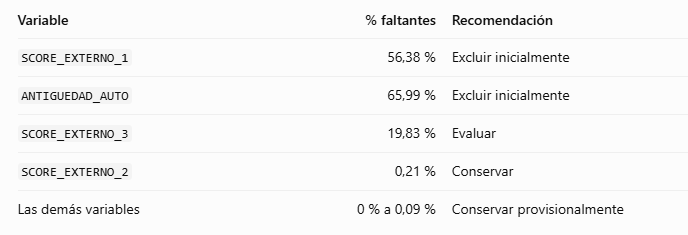

Otros hallazgos importantes:
- Ingresos: el máximo es 117 millones, frente a una mediana de 147.150. Hay valores extremos que debemos investigar.
- Antigüedad laboral: ANTIGUEDAD_LABORAL alcanza 365.243, un valor especial que representa información no disponible y no debe interpretarse como antigüedad real.
- Edad: EDAD_DIAS contiene valores negativos porque representa días anteriores a la solicitud.
- Montos financieros: presentan escalas muy diferentes, por lo que posteriormente necesitaremos estandarizarlos.

### 1.5. Revisar valores especiales y posibles outliers

In [70]:
# 1. Valor especial en antigüedad laboral
especiales = (df_cluster['ANTIGUEDAD_LABORAL'] == 365243).sum()

print("Casos con ANTIGUEDAD_LABORAL = 365243:", especiales)
print("Porcentaje:", round(especiales / len(df_cluster) * 100, 2), "%")

# 2. Distribución de ingresos
ingresos = df_cluster['INGRESO_TOTAL']

print("\nPercentiles de ingresos:")
print(ingresos.quantile([0.50, 0.90, 0.95, 0.99, 0.999, 1.00]))


Casos con ANTIGUEDAD_LABORAL = 365243: 55374
Porcentaje: 18.01 %

Percentiles de ingresos:
0.500       147150.0
0.900       270000.0
0.950       337500.0
0.990       472500.0
0.999       900000.0
1.000    117000000.0
Name: INGRESO_TOTAL, dtype: float64


Tenemos valores especiales y valores extremos que debemos tratar antes de aplicar Clúster.

1. Antigüedad laboral: valores especiales. El 55.374 observaciones (18,01 %) tienen ANTIGUEDAD_LABORAL = 365243. Es un código especial que debemos tratar como información no disponible. Ver si se reemplaza por NaN.

2. Ingresos: posibles outliers.

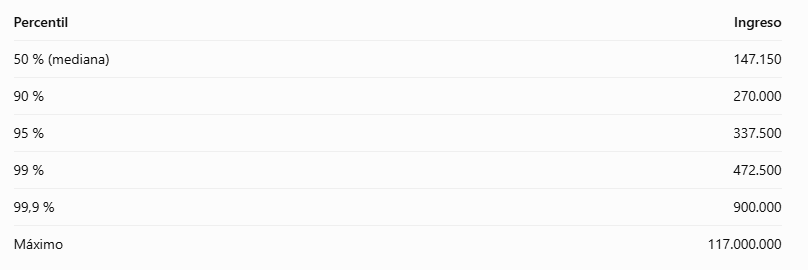

El 99 % de los solicitantes tiene ingresos iguales o inferiores a 472.500, mientras que el máximo alcanza 117 millones. Esto evidencia una distribución muy asimétrica, con valores extremos que podrían distorsionar las distancias euclídeas. Todavía no eliminaremos esos registros. Primero evaluaremos su impacto.

El siguiente paso será revisar las correlaciones entre nuestras variables candidatas, para detectar información redundante antes de definir cuáles conservaremos.

Después trataremos los valores faltantes, analizaremos los outliers multivariados (por ejemplo, mediante la distancia de Mahalanobis, vista en el material de clase) y estandarizaremos los datos.

### 1.6. Análisis de correlaciones entre variables métricas.

Calcular la matriz de correlaciones de Pearson y representarla mediante un mapa de calor.

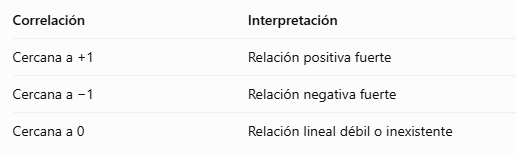

Para nuestro análisis de clústeres, prestaremos especial atención a correlaciones con valor absoluto superior a 0,80.

Por ejemplo, si MONTO_CREDITO y VALOR_BIENES están muy correlacionadas, podríamos conservar solamente una para evitar redundancia.

Porque en métodos basados en distancias euclídeas, incluir variables muy correlacionadas puede hacer que una misma dimensión financiera influya varias veces en la formación de los grupos.

Todavía no eliminamos variables por correlación. Primero analizaremos los resultados y justificaremos cualquier exclusión. Además, Pearson puede verse afectado por valores extremos, por lo que tendremos eso en cuenta.


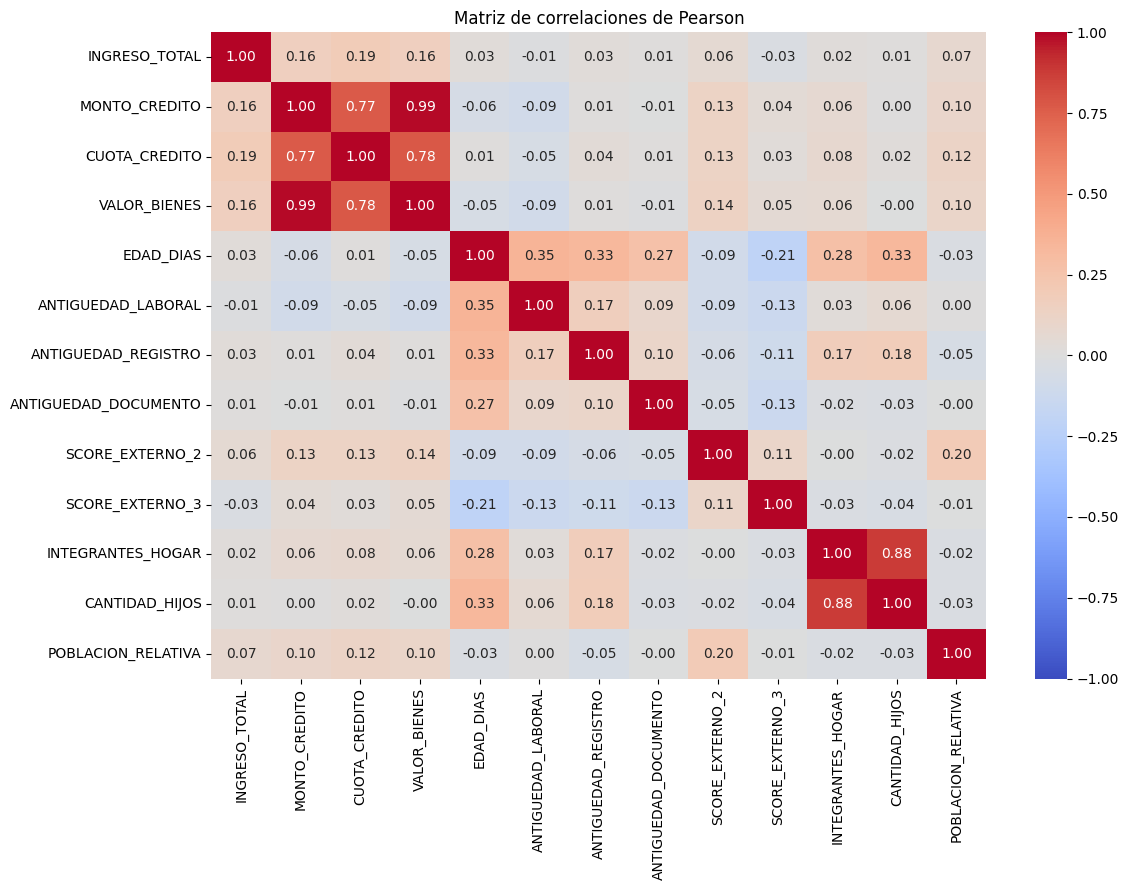

In [71]:
import seaborn as sns
import matplotlib.pyplot as plt

# Excluimos provisionalmente las dos variables
# con mayor porcentaje de faltantes
variables_analisis = [
    v for v in df_cluster.columns
    if v not in ['SCORE_EXTERNO_1', 'ANTIGUEDAD_AUTO']
]

# Creamos una copia para el análisis
df_corr = df_cluster[variables_analisis].copy()

# Reemplazamos el código especial por NaN
df_corr['ANTIGUEDAD_LABORAL'] = df_corr['ANTIGUEDAD_LABORAL'].replace(365243, float('nan'))

# Calculamos las correlaciones
matriz_corr = df_corr.corr(method='pearson')

# Gráfico
plt.figure(figsize=(12, 9))

sns.heatmap(
    matriz_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Matriz de correlaciones de Pearson')
plt.tight_layout()
plt.show()



### Interpretación de las correlaciones

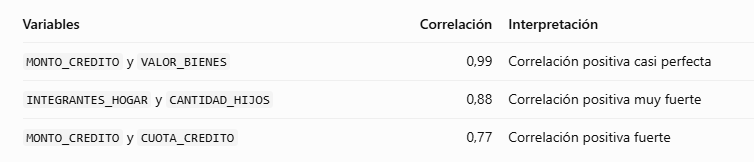

Se propone:

Eliminar VALOR_BIENES: aporta información muy similar al monto del crédito.

Eliminar INTEGRANTES_HOGAR: está fuertemente correlacionada con la cantidad de hijos. Conservaremos CANTIDAD_HIJOS.

Conservar provisionalmente CUOTA_CREDITO: aunque presenta una correlación de 0,77 con el monto del crédito, representa una dimensión financiera diferente: el importe de la cuota.

Las demás variables no presentan correlaciones lineales suficientemente elevadas como para justificar su eliminación únicamente por este criterio.

RESULTADO 11 VARIABLES CANDIDATAS (PARTIMOS DE 15, DONDE EXCLUÍMOS 2 POR DATOS FALTANTES Y 2 POR CORRELACIÓN).

Todavía no es una selección definitiva: debemos revisar valores extremos, faltantes y la pertinencia de cada variable.


## Preparación de los datos

Preparación de los datos (selección definitiva, tratamiento de faltantes, outliers y estandarización).

### 2.1. Actualizar nuestra selección

In [72]:
# Excluir variables con muchos faltantes o alta correlación
variables_excluir = [
    'SCORE_EXTERNO_1',
    'ANTIGUEDAD_AUTO',
    'VALOR_BIENES',
    'INTEGRANTES_HOGAR'
]

# Seleccionar las variables que conservaremos
variables_seleccionadas = [
    v for v in df_cluster.columns
    if v not in variables_excluir
]

# Crear una nueva base sin modificar la original
df_seleccion = df_cluster[variables_seleccionadas].copy()

# Tratar el valor especial de antigüedad laboral
df_seleccion['ANTIGUEDAD_LABORAL'] = (
    df_seleccion['ANTIGUEDAD_LABORAL'].replace(365243, float('nan'))
)

# Verificar dimensiones
print("Observaciones:", df_seleccion.shape[0])
print("Variables seleccionadas:", df_seleccion.shape[1])

# Faltantes después de la selección
display(
    (df_seleccion.isna().mean() * 100)
    .sort_values(ascending=False)
    .round(2)
)


Observaciones: 307511
Variables seleccionadas: 11


,0
SCORE_EXTERNO_3,19.83
ANTIGUEDAD_LABORAL,18.01
SCORE_EXTERNO_2,0.21
CUOTA_CREDITO,0.00
INGRESO_TOTAL,0.00
MONTO_CREDITO,0.00
EDAD_DIAS,0.00
ANTIGUEDAD_DOCUMENTO,0.00
ANTIGUEDAD_REGISTRO,0.00
CANTIDAD_HIJOS,0.00


Interpretación del resultado:

El código se ejecutó correctamente:
- 307.511 observaciones.
- 11 variables métricas seleccionadas.
- Los principales valores faltantes son:
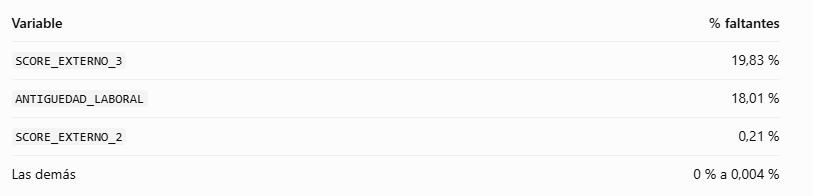

Tenemos una base con 11 variables candidatas y una cantidad importante de observaciones. Los faltantes se concentran principalmente en dos variables.

El siguiente paso será decidir cómo tratar esos valores faltantes, procurando conservar la mayor cantidad posible de información sin distorsionar los futuros clústeres.

### 2.2. Tratamiento de valores faltantes

Tenemos dos alternativas principales: eliminar observaciones incompletas o imputar valores faltantes mediante algún procedimiento estadístico.

Primero vemos cuántas observaciones perderíamos si elimináramos las filas incompletas. Después decidiremos si conviene imputar.

In [73]:
# Evaluación de valores faltantes

# Cantidad original de observaciones
n_original = len(df_seleccion)

# Observaciones sin ningún valor faltante
df_completos = df_seleccion.dropna()

n_completos = len(df_completos)

# Resultados
print("Observaciones originales:", n_original)
print("Observaciones completas:", n_completos)
print("Observaciones que se perderían:", n_original - n_completos)

print(
    "Porcentaje de observaciones perdidas:",
    round((n_original - n_completos) / n_original * 100, 2),
    "%"
)


Observaciones originales: 307511
Observaciones completas: 201916
Observaciones que se perderían: 105595
Porcentaje de observaciones perdidas: 34.34 %


Los resultados muestran que eliminar todas las observaciones incompletas implicaría perder una parte importante de la base.

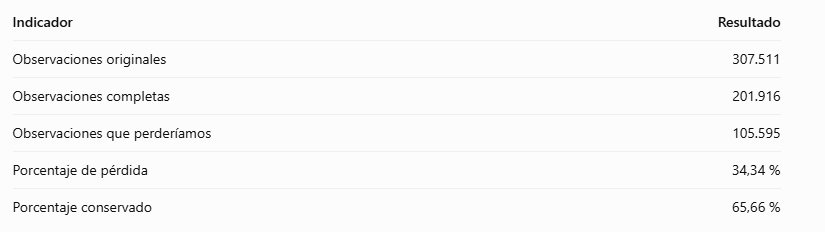

Aunque conservaríamos más de 200.000 observaciones, perderíamos el 34,34 % de la información.

Vamos a comprobar si los solicitantes con información incompleta presentan características diferentes de aquellos con información completa.

In [74]:
# Identificar observaciones completas e incompletas
df_revision = df_seleccion.copy()

df_revision['ESTADO_DATOS'] = df_revision.isna().any(axis=1).map({
    True: 'Incompletos',
    False: 'Completos'
})

# Comparar características de ambos grupos
comparacion = df_revision.groupby('ESTADO_DATOS')[
    ['INGRESO_TOTAL', 'MONTO_CREDITO',
     'CUOTA_CREDITO', 'EDAD_DIAS']
].median()

display(comparacion.round(2))


,INGRESO_TOTAL,MONTO_CREDITO,CUOTA_CREDITO,EDAD_DIAS
ESTADO_DATOS,,,,
Completos,157500.0,529348.5,25978.5,-14689.0
Incompletos,135000.0,472500.0,23175.0,-19972.0


Comprobar qué proporción de faltantes corresponde a SCORE_EXTERNO_3, a ANTIGUEDAD_LABORAL o a ambas simultáneamente.

In [75]:
# Analizar coincidencia de valores faltantes

faltante_score = df_seleccion['SCORE_EXTERNO_3'].isna()
faltante_laboral = df_seleccion['ANTIGUEDAD_LABORAL'].isna()

print("Solo falta SCORE_EXTERNO_3:",
      (faltante_score & ~faltante_laboral).sum())

print("Solo falta ANTIGUEDAD_LABORAL:",
      (~faltante_score & faltante_laboral).sum())

print("Faltan ambas variables:",
      (faltante_score & faltante_laboral).sum())

print("Ambas variables completas:",
      (~faltante_score & ~faltante_laboral).sum())


Solo falta SCORE_EXTERNO_3: 49896
Solo falta ANTIGUEDAD_LABORAL: 44305
Faltan ambas variables: 11069
Ambas variables completas: 202241


Comparación de distribuciones entre casos completos e incompletos

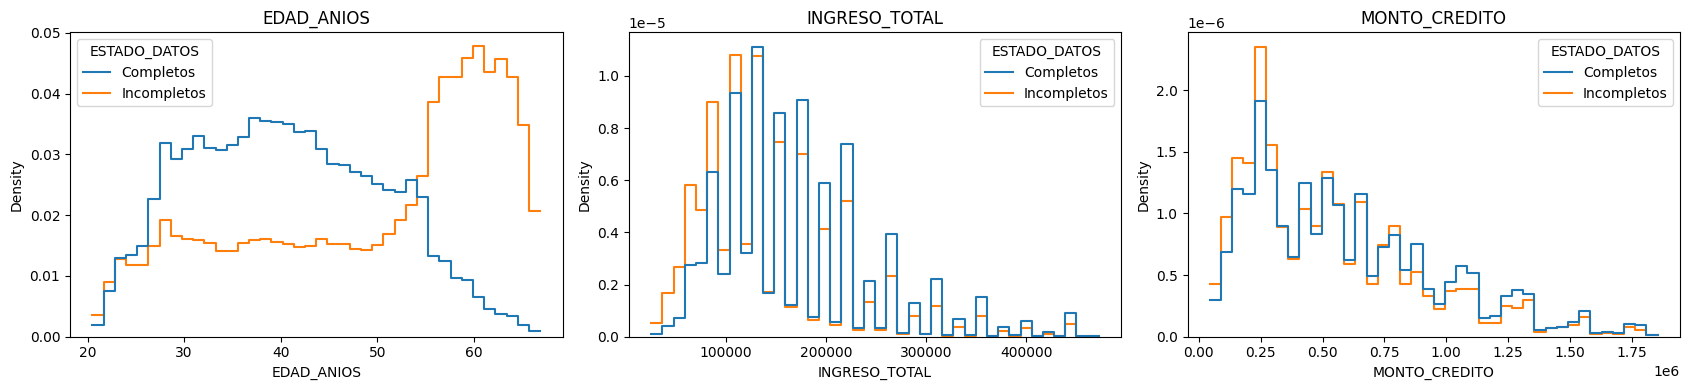

In [76]:
import matplotlib.pyplot as plt
import seaborn as sns

# Crear una copia para comparar los grupos
df_revision = df_seleccion.copy()

# Identificar registros completos e incompletos
df_revision['ESTADO_DATOS'] = df_revision.isna().any(axis=1).map({
    True: 'Incompletos',
    False: 'Completos'
})

# Convertir edad de días negativos a años positivos
df_revision['EDAD_ANIOS'] = -df_revision['EDAD_DIAS'] / 365.25

# Variables que vamos a comparar
variables_comparar = [
    'EDAD_ANIOS',
    'INGRESO_TOTAL',
    'MONTO_CREDITO'
]

# Graficar distribuciones
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

for i, variable in enumerate(variables_comparar):
    datos = df_revision[
        ['ESTADO_DATOS', variable]
    ].dropna().copy()

    # Limitar visualización al percentil 99
    limite = datos[variable].quantile(0.99)
    datos = datos[datos[variable] <= limite]

    sns.histplot(
        data=datos,
        x=variable,
        hue='ESTADO_DATOS',
        stat='density',
        common_norm=False,
        element='step',
        fill=False,
        bins=40,
        ax=axes[i]
    )

    axes[i].set_title(variable)

plt.tight_layout()
plt.show()


interpretación de resultados:

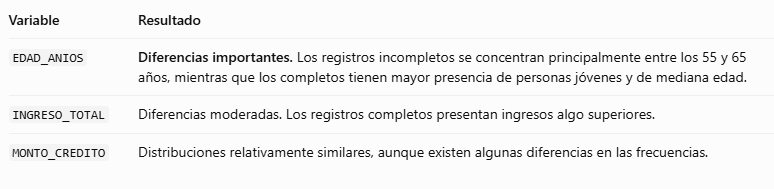

La principal diferencia está en la edad. Esto confirma que eliminar los registros incompletos podría producir una muestra con mayor representación de solicitantes jóvenes.

Por lo tanto, los valores faltantes no parecen distribuirse de manera completamente independiente de las características de los solicitantes, aunque estos gráficos no permiten determinar formalmente el mecanismo de ausencia.

Dada la situación y para realizar un análisis más riguroso delimitación de la población de estudio por edad.

Evaluamos si es conveniente trabajar con solicitantes de crédito de 25 a 55 años (datos más completos).

In [77]:
# 1. Crear una copia de la base seleccionada
df_edad = df_seleccion.copy()

# 2. Convertir la edad de días negativos a años positivos
df_edad['EDAD_ANIOS'] = -df_edad['EDAD_DIAS'] / 365.25

# 3. Filtrar solicitantes entre 25 y 55 años
df_25_55 = df_edad[
    df_edad['EDAD_ANIOS'].between(25, 55)
].copy()

# 4. Calcular observaciones completas e incompletas
n_total = len(df_25_55)
n_completos = len(df_25_55.dropna())
n_incompletos = n_total - n_completos

# 5. Mostrar resultados
print("Observaciones entre 25 y 55 años:", n_total)
print("Observaciones completas:", n_completos)
print("Observaciones incompletas:", n_incompletos)

print(
    "Porcentaje de registros incompletos:",
    round(n_incompletos / n_total * 100, 2), "%"
)

# 6. Porcentaje de faltantes por variable
display(
    (df_25_55.isna().mean() * 100)
    .sort_values(ascending=False)
    .round(2)
)


Observaciones entre 25 y 55 años: 226880
Observaciones completas: 177473
Observaciones incompletas: 49407
Porcentaje de registros incompletos: 21.78 %


,0
SCORE_EXTERNO_3,19.32
ANTIGUEDAD_LABORAL,3.00
SCORE_EXTERNO_2,0.19
CUOTA_CREDITO,0.00
EDAD_DIAS,0.00
MONTO_CREDITO,0.00
INGRESO_TOTAL,0.00
ANTIGUEDAD_REGISTRO,0.00
ANTIGUEDAD_DOCUMENTO,0.00
CANTIDAD_HIJOS,0.00


Entonces decidimos quedarnos con la población de 25 a 55 años.

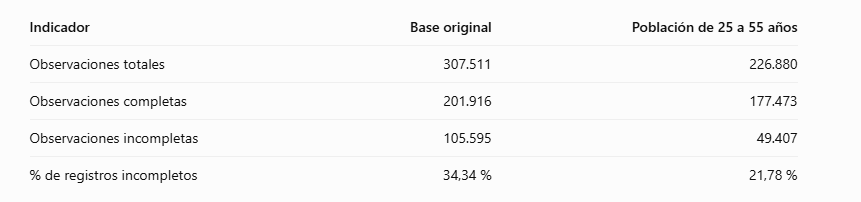

- Conservamos 226.880 solicitantes, aproximadamente el 73,8 % de la base original.

- El porcentaje de registros incompletos disminuye del 34,34 % al 21,78 %.

- ANTIGUEDAD_LABORAL mejora considerablemente: solamente tiene un 3 % de faltantes.

- SCORE_EXTERNO_3 sigue presentando un 19,32 % de faltantes.

Esto confirma que la delimitación por edad reduce significativamente el problema de los datos faltantes, especialmente en antigüedad laboral.

Nos queda verificar ahora si conviene conservar SCORE_EXTERNO_3, porque sigue teniendo casi un 20 % de faltantes. Ver cuanto aporta al análisis.

Y una vez decididas las variables definitivas, tratar los faltantes restantes. Y luego continuar con detección de outliers y estandarización.

In [78]:
# Evaluación de SCORE_EXTERNO_3

# 1. Estadísticas descriptivas
print("Estadísticas de SCORE_EXTERNO_3:")
display(df_25_55['SCORE_EXTERNO_3'].describe())

# 2. Comparación entre registros con y sin SCORE_EXTERNO_3
df_revision_score = df_25_55.copy()

df_revision_score['ESTADO_SCORE'] = (
    df_revision_score['SCORE_EXTERNO_3']
    .isna()
    .map({True: 'Sin score', False: 'Con score'})
)

comparacion_score = df_revision_score.groupby('ESTADO_SCORE')[
    ['INGRESO_TOTAL', 'MONTO_CREDITO',
     'CUOTA_CREDITO', 'EDAD_ANIOS']
].median()

print("\nComparación de características:")
display(comparacion_score.round(2))

# 3. Correlaciones con otras variables métricas
correlaciones_score = (
    df_25_55.corr(numeric_only=True)['SCORE_EXTERNO_3']
    .drop('SCORE_EXTERNO_3')
    .sort_values()
)

print("\nCorrelaciones con SCORE_EXTERNO_3:")
display(correlaciones_score.round(3))


Estadísticas de SCORE_EXTERNO_3:


,SCORE_EXTERNO_3
count,183047.000000
mean,0.503165
std,0.195144
min,0.000527
25%,0.360613
50%,0.526295
75%,0.659406
max,0.893976



Comparación de características:


,INGRESO_TOTAL,MONTO_CREDITO,CUOTA_CREDITO,EDAD_ANIOS
ESTADO_SCORE,,,,
Con score,157500.0,535500.0,26086.5,39.93
Sin score,135000.0,495000.0,25537.5,39.10



Correlaciones con SCORE_EXTERNO_3:


,SCORE_EXTERNO_3
EDAD_DIAS,-0.145
ANTIGUEDAD_LABORAL,-0.112
ANTIGUEDAD_REGISTRO,-0.082
ANTIGUEDAD_DOCUMENTO,-0.066
INGRESO_TOTAL,-0.024
CANTIDAD_HIJOS,-0.018
POBLACION_RELATIVA,-0.010
CUOTA_CREDITO,0.036
MONTO_CREDITO,0.052
SCORE_EXTERNO_2,0.110


Evaluación del score:

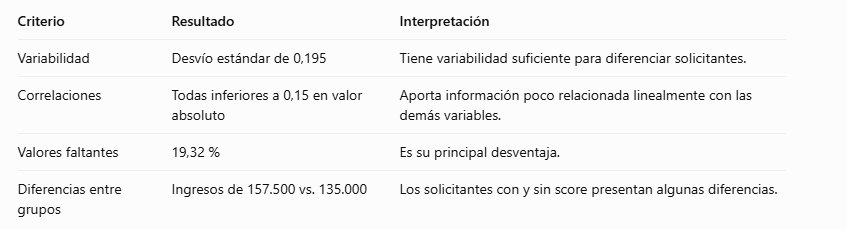

Se concluye que conservaríamos provisporiamente la variable. Tiene poca correlación entre las variables y puede aportar información relevante para identificar perfiles.

Pero no sabesmos igual como mejora la formación de cluster eso lo podemos evaluar más adelante comprando soluciones con o sin la variable.


Evaluar la población de 25 a 55 años para ver datos faltantes.

In [79]:
# 1. Crear una copia de la base seleccionada
df_edad = df_seleccion.copy()

# 2. Convertir la edad de días negativos a años positivos
df_edad['EDAD_ANIOS'] = -df_edad['EDAD_DIAS'] / 365.25

# 3. Filtrar solicitantes entre 25 y 55 años
df_25_55 = df_edad[
    df_edad['EDAD_ANIOS'].between(25, 55)
].copy()

# 4. Calcular observaciones completas e incompletas
n_total = len(df_25_55)
n_completos = len(df_25_55.dropna())
n_incompletos = n_total - n_completos

# 5. Mostrar resultados
print("Observaciones entre 25 y 55 años:", n_total)
print("Observaciones completas:", n_completos)
print("Observaciones incompletas:", n_incompletos)

print(
    "Porcentaje de registros incompletos:",
    round(n_incompletos / n_total * 100, 2), "%"
)

# 6. Porcentaje de faltantes por variable
display(
    (df_25_55.isna().mean() * 100)
    .sort_values(ascending=False)
    .round(2)
)


Observaciones entre 25 y 55 años: 226880
Observaciones completas: 177473
Observaciones incompletas: 49407
Porcentaje de registros incompletos: 21.78 %


,0
SCORE_EXTERNO_3,19.32
ANTIGUEDAD_LABORAL,3.00
SCORE_EXTERNO_2,0.19
CUOTA_CREDITO,0.00
EDAD_DIAS,0.00
MONTO_CREDITO,0.00
INGRESO_TOTAL,0.00
ANTIGUEDAD_REGISTRO,0.00
ANTIGUEDAD_DOCUMENTO,0.00
CANTIDAD_HIJOS,0.00


Se decidió excluir la variable SCORE_EXTERNO_3, dado que presenta un 19,32 % de valores faltantes en la población seleccionada de 25 a 55 años.

Si bien esta variable podría aportar información relevante para caracterizar los perfiles crediticios, su inclusión requeriría eliminar una proporción considerable de observaciones o aplicar procedimientos de imputación.

Considerando que se dispone de otras variables financieras y del indicador SCORE_EXTERNO_2, se optó por excluirla para simplificar el tratamiento de los datos y evitar posibles distorsiones derivadas de la imputación.

De esta manera, la base de análisis queda conformada por 10 variables métricas, manteniendo una cantidad elevada de observaciones para aplicar los métodos de conglomerados.

También eliminamos EDAD_DIAS porque ya tenemos EDAD_ANIOS, que representa la misma información en una unidad más interpretable.

Resultado por el momento:
- 226.880 observaciones.
- 10 variables métricas.
- Los faltantes se concentrarán principalmente en ANTIGUEDAD_LABORAL (3 %).

In [80]:
# Excluir SCORE_EXTERNO_3 de la base de análisis
df_final = df_25_55.drop(
    columns=['SCORE_EXTERNO_3', 'EDAD_DIAS']
).copy()

# Verificar dimensiones
print("Observaciones:", df_final.shape[0])
print("Variables:", df_final.shape[1])

# Verificar valores faltantes
display(
    (df_final.isna().mean() * 100)
    .sort_values(ascending=False)
    .round(2)
)

Observaciones: 226880
Variables: 10


,0
ANTIGUEDAD_LABORAL,3.00
SCORE_EXTERNO_2,0.19
CUOTA_CREDITO,0.00
INGRESO_TOTAL,0.00
MONTO_CREDITO,0.00
ANTIGUEDAD_REGISTRO,0.00
ANTIGUEDAD_DOCUMENTO,0.00
CANTIDAD_HIJOS,0.00
POBLACION_RELATIVA,0.00
EDAD_ANIOS,0.00


De esta forma quedó la base:

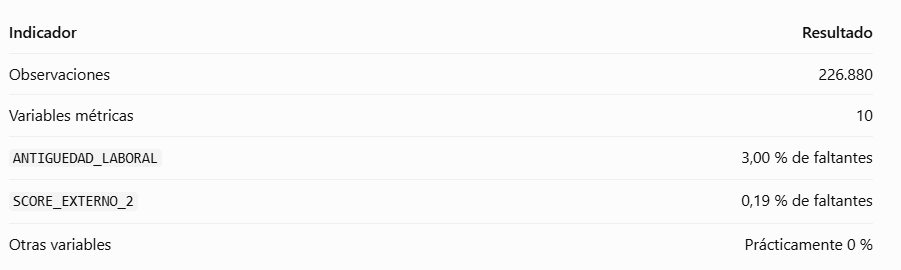

Y dado que los datos faltantes que quedaron representarn una prporción pequeña de la base, decidimos revisar la cantidad de datos que representa para luego eliminar las observaciones que todavía contienen valores faltantes en el caso que no sean representativas.

In [81]:
# Evaluar la pérdida de registros por valores faltantes

n_original = len(df_final)
n_completos = len(df_final.dropna())

print("Observaciones actuales:", n_original)
print("Observaciones completas:", n_completos)
print("Observaciones a eliminar:", n_original - n_completos)

print(
    "Porcentaje de pérdida:",
    round((n_original - n_completos) / n_original * 100, 2),
    "%"
)


Observaciones actuales: 226880
Observaciones completas: 219655
Observaciones a eliminar: 7225
Porcentaje de pérdida: 3.18 %


A partir del resultado, se decide trabajar con los 219.655 registros completos.

In [82]:
# Crear base definitiva sin valores faltantes
df_limpia = df_final.dropna().copy()

# Verificar dimensiones
print("Observaciones:", df_limpia.shape[0])
print("Variables:", df_limpia.shape[1])

# Comprobar que no quedan valores faltantes
print("Valores faltantes:", df_limpia.isna().sum().sum())

# Verificar las primeras observaciones
display(df_limpia.head())

Observaciones: 219655
Variables: 10
Valores faltantes: 0


,INGRESO_TOTAL,MONTO_CREDITO,CUOTA_CREDITO,ANTIGUEDAD_LABORAL,ANTIGUEDAD_REGISTRO,ANTIGUEDAD_DOCUMENTO,SCORE_EXTERNO_2,CANTIDAD_HIJOS,POBLACION_RELATIVA,EDAD_ANIOS
0,202500.0,406597.5,24700.5,-637.0,-3648.0,-2120,0.262949,0,0.018801,25.902806
1,270000.0,1293502.5,35698.5,-1188.0,-1186.0,-291,0.622246,0,0.003541,45.900068
2,67500.0,135000.0,6750.0,-225.0,-4260.0,-2531,0.555912,0,0.010032,52.145106
3,135000.0,312682.5,29686.5,-3039.0,-9833.0,-2437,0.650442,0,0.008019,52.032854
4,121500.0,513000.0,21865.5,-3038.0,-4311.0,-3458,0.322738,0,0.028663,54.570842


Creamos df_limpia, que conserva las 10 variables métricas y 219.655 observaciones completas.

### 2.3. Detección de valores atípicos (outliers).

Detección de outliers mediante Mahalanobis:
La distancia de Mahalanobis permite identificar observaciones que presentan características inusuales considerando simultáneamente las 10 variables métricas y sus correlaciones.

- Calcular el vector de medias.
- Calcular la matriz de covarianzas.
- Calcular la distancia de Mahalanobis al cuadrado (D^2).
- Compararla con el valor crítico de una distribución chi-cuadrado.
Utilizaremos un nivel de significación del 1 % (alpha=0,01).

In [83]:
import numpy as np
import pandas as pd
from scipy.stats import chi2

# 1. Vector de medias
media = df_limpia.mean()

# 2. Matriz de covarianzas
Sx = df_limpia.cov()

# 3. Distancia de Mahalanobis al cuadrado
X = df_limpia.to_numpy()
diferencias = X - media.to_numpy()

Sx_inv = np.linalg.pinv(Sx.to_numpy())

D2 = np.einsum(
    'ij,jk,ik->i',
    diferencias, Sx_inv, diferencias
)

# 4. Valor crítico chi-cuadrado
n_variables = df_limpia.shape[1]
valor_critico = chi2.ppf(0.99, df=n_variables)

# 5. Identificar posibles outliers
outliers = D2 > valor_critico

print("Valor crítico:", round(valor_critico, 2))
print("Cantidad de posibles outliers:", outliers.sum())
print("Porcentaje de posibles outliers:",
      round(outliers.mean() * 100, 2), "%")


Valor crítico: 23.21
Cantidad de posibles outliers: 5887
Porcentaje de posibles outliers: 2.68 %


Interpretación de resultado:
- Si (D^2) supera el valor crítico, la observación se identifica como posible outlier multivariado.
- Si no lo supera, no se identifica como atípica según este criterio.

Mahalanobis es sensible a valores extremos y a la forma de la distribución. La comparación con chi-cuadrado es una aproximación que requiere ciertos supuestos, especialmente normalidad multivariada. Por eso, los casos detectados serán candidatos a revisión, no observaciones que debamos eliminar automáticamente.

Se identificaron 5.887 observaciones potencialmente atípicas, que representan el 2,68 % de la muestra.

Es una proporción relativamente pequeña, pero eso no significa que debamos eliminarlas automáticamente.

Además, la interpretación del umbral chi-cuadrado depende de supuestos como la normalidad multivariada, que todavía no verificamos.

Entonces comparamos los perfiles financieros de ambos grupos para identificar qué características podrían explicar las distancias elevadas.

In [84]:
# Comparar observaciones normales y posibles outliers

df_outliers = df_limpia.copy()

# Clasificar las observaciones
df_outliers['TIPO_OBSERVACION'] = np.where(
    outliers, 'Posible outlier', 'Normal'
)

# Comparar medianas por grupo
comparacion_outliers = df_outliers.groupby(
    'TIPO_OBSERVACION'
).median(numeric_only=True)

display(comparacion_outliers.round(2))


,INGRESO_TOTAL,MONTO_CREDITO,CUOTA_CREDITO,ANTIGUEDAD_LABORAL,ANTIGUEDAD_REGISTRO,ANTIGUEDAD_DOCUMENTO,SCORE_EXTERNO_2,CANTIDAD_HIJOS,POBLACION_RELATIVA,EDAD_ANIOS
TIPO_OBSERVACION,,,,,,,,,,
Normal,157500.0,521280.0,25785.0,-1671.0,-4198.0,-2862.0,0.57,0.0,0.02,39.35
Posible outlier,256500.0,941580.0,55777.5,-2627.0,-4816.0,-2707.0,0.64,0.0,0.03,43.70


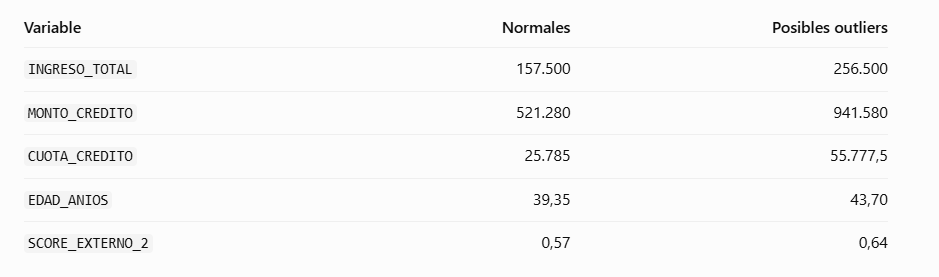

Los posibles outliers presentan, en términos de medianas:
- Ingresos 62,9 % superiores.
- Montos de crédito 80,6 % superiores.
- Cuotas aproximadamente 116 % superiores.
- Una edad ligeramente mayor.
Esto sugiere que muchos de los casos identificados podrían corresponder a solicitantes con perfiles financieros de mayor magnitud (que hasta podrían ser relevantes para identificar mediante clústeres), y no necesariamente a errores en los datos.

Sin embargo, las medianas no permiten identificar por sí solas qué variables explican cada distancia de Mahalanobis elevada.

Antes de tomar una decisión definitiva, haría una última comprobación: revisar los valores extremos de las principales variables financieras para detectar posibles errores o magnitudes desproporcionadas (ingresos, montos de crédito y cuotas de crédito). Ya que los métodos de clústeres que podríamos utilizar, especialmente Ward y K-means, son sensibles a los valores extremos.

In [85]:
# Análisis de valores extremos

# Seleccionar variables financieras
variables_financieras = [
    'INGRESO_TOTAL',
    'MONTO_CREDITO',
    'CUOTA_CREDITO'
]

# Calcular percentiles
percentiles = df_limpia[variables_financieras].quantile(
    [0.50, 0.90, 0.95, 0.99, 0.999, 1.00]
)

# Mostrar resultados
display(percentiles.T.round(2))

,0.500,0.900,0.950,0.990,0.999,1.000
INGRESO_TOTAL,157500.0,279000.0,360000.0,540000.0,994091.80,117000000.0
MONTO_CREDITO,522000.0,1168452.0,1350000.0,1886850.0,2517300.00,4050000.0
CUOTA_CREDITO,26086.5,46836.9,53712.0,70879.5,110774.89,258025.5


In [86]:
# Evaluar que cantidad de valores extremos presenta la variable INGRESO_TOTAL

variable = 'INGRESO_TOTAL'

limite = df_limpia[variable].quantile(0.999)
cantidad = (df_limpia[variable] > limite).sum()

print(f"Límite P99,9: {limite:,.2f}")
print(f"Registros afectados: {cantidad}")
print(f"Porcentaje: {cantidad / len(df_limpia) * 100:.3f}%")

Límite P99,9: 994,091.80
Registros afectados: 220
Porcentaje: 0.100%


Dado que se ve que la variable INGRESO_TOTAL presenta un valor máximo extremadamente elevado (117 millones). Entiendo que es un outlier. Se decide reemplazar todos los valores superiores al percentil 99,9 por el valor de ese percentil. Dado que también solo 220 observaciones (0,10 %) superan el percentil 99,9 de INGRESO_TOTAL.

- Percentil 99,9: 994.091,80
- Máximo original: 117.000.000
- Quedando el máximo después de winsorizar: 994.091,80


In [87]:
# Crear una copia para conservar los datos originales
df_tratada = df_limpia.copy()

# Calcular el percentil 99,9
limite = df_tratada['INGRESO_TOTAL'].quantile(0.999)

# Aplicar winsorización únicamente a INGRESO_TOTAL
df_tratada['INGRESO_TOTAL'] = (
    df_tratada['INGRESO_TOTAL'].clip(upper=limite)
)

# Verificar resultados
print("Máximo original:", df_limpia['INGRESO_TOTAL'].max())
print("Máximo después:", df_tratada['INGRESO_TOTAL'].max())
print("Observaciones:", len(df_tratada))


Máximo original: 117000000.0
Máximo después: 994091.7960002313
Observaciones: 219655


Quedando asi la base preparada para la estandarización que sería el siguiente paso:

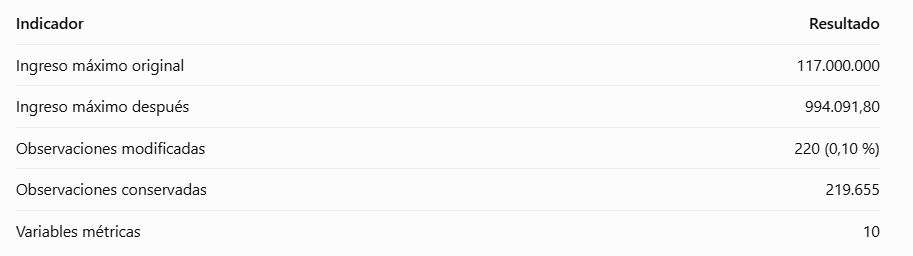

### 2.4. Estandarización de las variables métricas

Estandarizar, corregir el efecto de las 10 variables mediante puntuaciones Z.

Esto es necesario porque tenemos variables medidas en distintas escalas: ingresos, montos de crédito, días, años, cantidades e índices.

La estandarización permitirá que todas tengan media aproximadamente 0 y desviación estándar 1, evitando que las variables con valores numéricos más grandes dominen las distancias euclídeas.

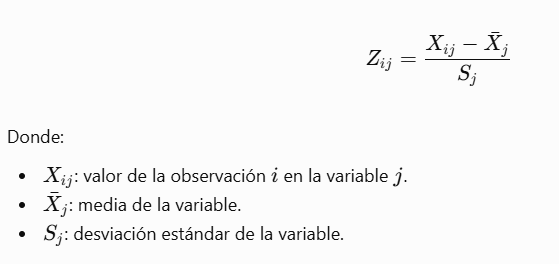

Con la estandarización, todas las variables tendrán una escala comparable, aunque eso no garantiza que todas tengan la misma importancia conceptual.

Este procedimiento es fundamental para los métodos que aplicaremos después:
- Métodos jerárquicos: Ward, vecino más cercano, vecino más lejano, promedio y centroide.
- Método no jerárquico: K-means.
Todos ellos podrán utilizar los datos estandarizados para calcular distancias entre solicitantes.


In [88]:
# Estandarización mediante puntuaciones Z

from sklearn.preprocessing import StandardScaler
import pandas as pd

# Crear el estandarizador
escalador = StandardScaler()

# Estandarizar las 10 variables métricas
datos_estandarizados = escalador.fit_transform(df_tratada)

# Crear una nueva base con los nombres originales de las columnas
df_estandarizada = pd.DataFrame(
    datos_estandarizados,
    columns=df_tratada.columns,
    index=df_tratada.index
)

# Verificar dimensiones
print("Observaciones:", df_estandarizada.shape[0])
print("Variables:", df_estandarizada.shape[1])

# Comprobar medias y desviaciones estándar
verificacion = pd.DataFrame({
    'MEDIA': df_estandarizada.mean(),
    'DESVIO_ESTANDAR': df_estandarizada.std(ddof=0)
})

display(verificacion.round(4))


Observaciones: 219655
Variables: 10


,MEDIA,DESVIO_ESTANDAR
INGRESO_TOTAL,0.0,1.0
MONTO_CREDITO,-0.0,1.0
CUOTA_CREDITO,0.0,1.0
ANTIGUEDAD_LABORAL,-0.0,1.0
ANTIGUEDAD_REGISTRO,-0.0,1.0
ANTIGUEDAD_DOCUMENTO,-0.0,1.0
SCORE_EXTERNO_2,0.0,1.0
CANTIDAD_HIJOS,0.0,1.0
POBLACION_RELATIVA,0.0,1.0
EDAD_ANIOS,0.0,1.0


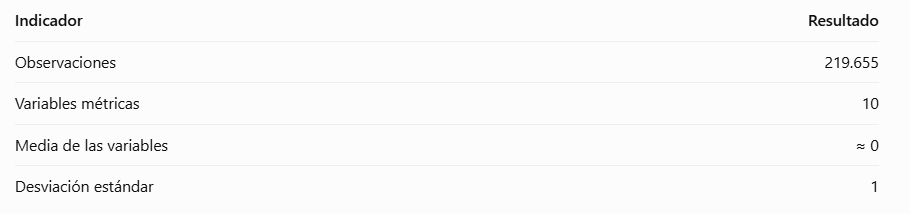

Las 10 variables fueron estandarizadas mediante puntuaciones Z, obteniendo una media aproximadamente igual a cero y una desviación estándar igual a uno.

Esto permite comparar las observaciones en una escala común y evita que las diferencias de unidades de medida dominen el cálculo de las distancias euclídeas.

## 4. Aplicación de métodos jerárquicos

Aplicación de métodos jerárquicos (Cálculo de distancias euclídeas. Métodos de agrupamiento: vecino más cercano, vecino más lejano, promedio, centroide y Ward. Construcción e interpretación de dendrogramas. Comparación de métodos.)

### 4.1. Selección y evaluación de la muestra

Como tenemos 219.655 observaciones, utilizaremos una muestra aleatoria reproducible de aproximadamente 1.500 solicitantes para el análisis jerárquico. Esto permitirá calcular las distancias sin sobrecargar. Además comprobaremos si conserva características similares a la población original.

In [89]:
# Selección de una muestra para el análisis jerárquico

# 1. Seleccionar una muestra aleatoria de 1.500 observaciones
df_muestra = df_estandarizada.sample(
    n=1500,
    random_state=42
).copy()

# 2. Verificar dimensiones
print("Observaciones de la población:", len(df_estandarizada))
print("Observaciones de la muestra:", len(df_muestra))
print("Variables:", df_muestra.shape[1])

# 3. Comparar medias de la población y la muestra
comparacion_muestra = pd.DataFrame({
    'MEDIA_POBLACION': df_estandarizada.mean(),
    'MEDIA_MUESTRA': df_muestra.mean(),
    'DESVIO_POBLACION': df_estandarizada.std(),
    'DESVIO_MUESTRA': df_muestra.std()
})

display(comparacion_muestra.round(3))


Observaciones de la población: 219655
Observaciones de la muestra: 1500
Variables: 10


,MEDIA_POBLACION,MEDIA_MUESTRA,DESVIO_POBLACION,DESVIO_MUESTRA
INGRESO_TOTAL,0.0,-0.001,1.0,0.909
MONTO_CREDITO,-0.0,0.007,1.0,0.988
CUOTA_CREDITO,0.0,0.009,1.0,0.970
ANTIGUEDAD_LABORAL,-0.0,0.000,1.0,0.995
ANTIGUEDAD_REGISTRO,-0.0,0.005,1.0,1.005
ANTIGUEDAD_DOCUMENTO,-0.0,0.003,1.0,1.038
SCORE_EXTERNO_2,0.0,0.010,1.0,1.001
CANTIDAD_HIJOS,0.0,-0.016,1.0,0.984
POBLACION_RELATIVA,0.0,0.041,1.0,1.045
EDAD_ANIOS,0.0,0.028,1.0,0.982


- Medias: todas están muy próximas a 0.
- Desviaciones estándar: están próximas a 1, con valores entre 0,909 y 1,045.
- Variables: conservamos las 10 variables métricas seleccionadas.

Esto indica que la muestra mantiene características descriptivas similares a la población, aunque no garantiza representatividad absoluta podemos utilizar esta muestra para aplicar los métodos jerárquicos.

### 4.2. Cálculo de distancias euclídeas

Necesitamos calcular las distancias entre los solicitantes para determinar cuáles presentan características similares.

In [90]:
from scipy.spatial.distance import pdist, squareform

# 1. Calcular distancias euclídeas entre observaciones
distancias = pdist(df_muestra, metric='euclidean')

# 2. Construir matriz de distancias
matriz_distancias = squareform(distancias)

# 3. Verificar dimensiones
print("Dimensiones de la matriz:", matriz_distancias.shape)

# 4. Visualizar las distancias entre las primeras 5 observaciones
display(
    pd.DataFrame(
        matriz_distancias[:5, :5],
        index=df_muestra.index[:5],
        columns=df_muestra.index[:5]
    ).round(3)
)


Dimensiones de la matriz: (1500, 1500)


,45974,306160,79941,243604,224078
45974,0.000,2.594,4.154,6.249,4.452
306160,2.594,0.000,4.588,6.736,4.605
79941,4.154,4.588,0.000,5.160,4.355
243604,6.249,6.736,5.160,0.000,7.387
224078,4.452,4.605,4.355,7.387,0.000


- pdist() calcula las distancias euclídeas entre todos los pares de solicitantes.
- squareform() organiza esas distancias en una matriz cuadrada.

Visualizamos una pequeña parte de la matriz para interpretar los resultados.

- La diagonal principal contiene ceros, porque cada observación tiene distancia cero consigo misma.
- La matriz es simétrica.
- Las distancias menores indican solicitantes más similares según las 10 variables estandarizadas.

Interpretación del resultado:
- Dimensiones: 1.500 × 1.500.
- Diagonal principal: todos los valores son 0.
- Simetría: la distancia entre dos solicitantes es igual en ambos sentidos.
- Distancias: cuanto menor es el valor, mayor es la similitud entre los solicitantes según las 10 variables.
Por ejemplo, las observaciones 45974 y 306160 tienen una distancia de 2,594, por lo que son más similares entre sí que 45974 y 243604, cuya distancia es 6,249.

Cada observación representa un solicitante de crédito y contiene los valores de sus 10 variables métricas, como ingresos, monto del crédito, edad, antigüedad laboral, etc.

La distancia euclídea compara simultáneamente esos 10 valores entre dos solicitantes.
- Menor distancia: los solicitantes tienen características más similares.
- Mayor distancia: sus características son más diferentes.
Como ya estandarizamos las variables, podemos compararlas en una escala común.

### 4.3. Aplicación de los métodos jerárquicos

Utilizaremos la matriz de distancias euclídeas que calculamos anteriormente para formar los primeros conglomerados.

Aplicaremos el método jerárquico de Ward y dendrogramas.

Este método agrupa observaciones buscando minimizar el incremento de la variabilidad interna de los conglomerados (suma de cuadrados). Es decir, busca formar grupos relativamente homogéneos en cada fusión.

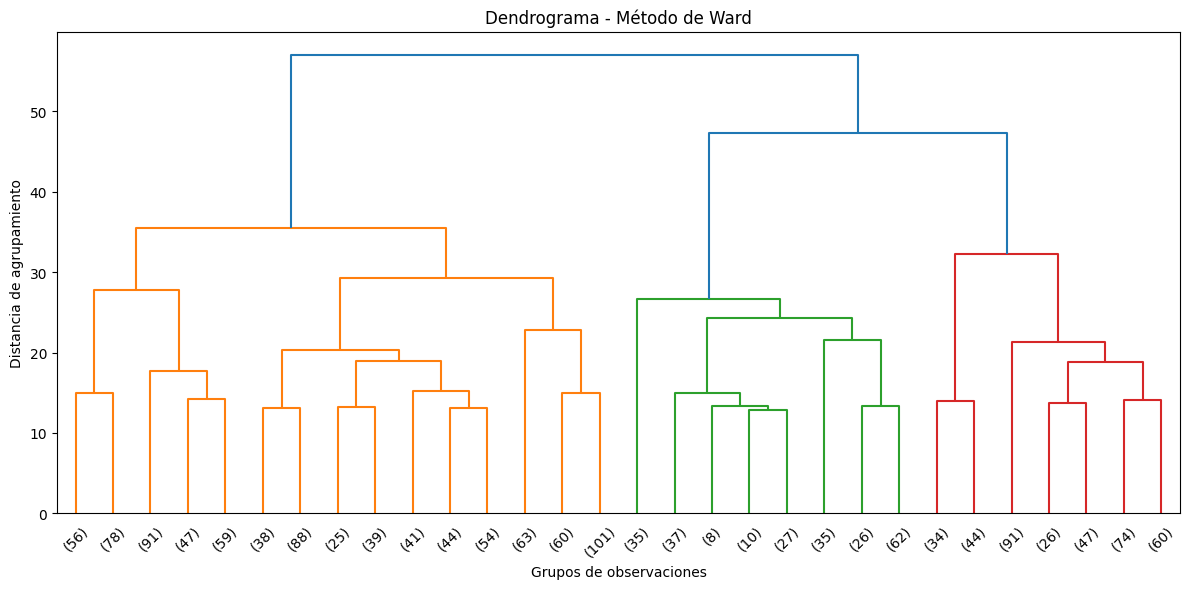

In [91]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

# 1. Aplicar el método jerárquico de Ward
modelo_ward = linkage(
    distancias,
    method='ward'
)

# 2. Construir el dendrograma
plt.figure(figsize=(12, 6))

dendrogram(
    modelo_ward,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True
)

plt.title('Dendrograma - Método de Ward')
plt.xlabel('Grupos de observaciones')
plt.ylabel('Distancia de agrupamiento')
plt.tight_layout()
plt.show()


El dendrograma nos permite visualizar cómo se forman los grupos y explorar cuántos conglomerados podrían existir, pero todavía no nos dice qué características financieras tiene cada uno. Eso lo analizaremos posteriormente. Ni tampoco determinar una cantidad óptima de clústers.

A distancias bajas (por ejemplo, 10), tenemos muchos clústeres pequeños y generalmente más homogéneos.

A medida que aumenta la altura, los clústeres se fusionan y disminuye su cantidad.

Cuanto más arriba se fusionan, mayor es la diferencia entre los grupos que estamos uniendo.

Para determinar el número óptimo de clústers se utilizará más adelante:
- Índice de Davies-Bouldin (DB).
- Índice de Dunn.
- Índice de Calinski-Harabasz (CH).
- Estadístico de Hubert y Dindex.

Estos indicadores nos ayudarán a comparar distintas cantidades de clústeres.Buscando un equilibrio entre la homogeneidad dentro de cada grupo y las diferencias entre grupos. No queremos demasiados clústeres pequeños ni tan pocos que agrupemos solicitantes muy diferentes.

### 4.4. Aplicación de los otros métodos jerárquicos

Los métodos a utilizar serían:

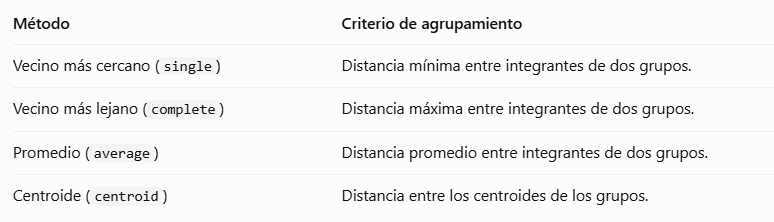


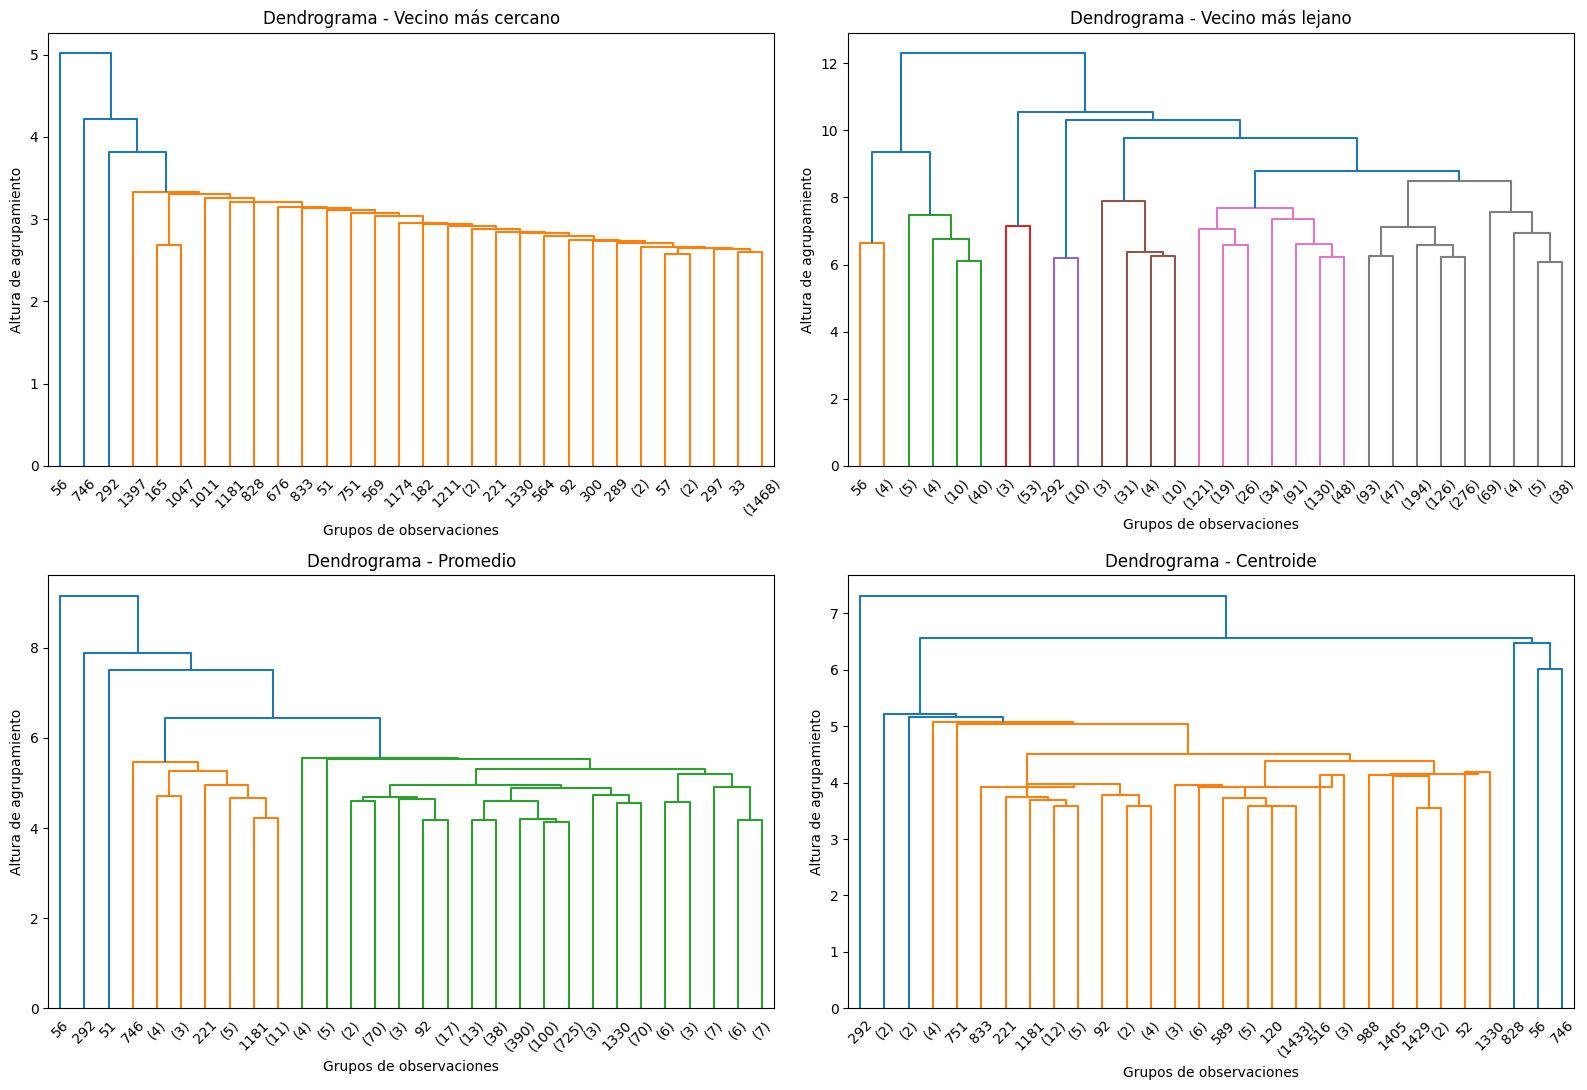

In [92]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

# Métodos jerárquicos a comparar
metodos = {
    'Vecino más cercano': 'single',
    'Vecino más lejano': 'complete',
    'Promedio': 'average',
    'Centroide': 'centroid'
}

# Aplicar los cuatro métodos y guardar los resultados
modelos_jerarquicos = {'Ward': modelo_ward}

for nombre, metodo in metodos.items():
    modelos_jerarquicos[nombre] = linkage(
        distancias,
        method=metodo
    )

# Graficar los cuatro dendrogramas
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

for ax, (nombre, modelo) in zip(
    axes.flatten(),
    list(modelos_jerarquicos.items())[1:]
):
    dendrogram(
        modelo,
        truncate_mode='lastp',
        p=30,
        show_leaf_counts=True,
        ax=ax
    )

    ax.set_title(f'Dendrograma - {nombre}')
    ax.set_xlabel('Grupos de observaciones')
    ax.set_ylabel('Altura de agrupamiento')

plt.tight_layout()
plt.show()


La comparación visual de los dendrogramas evidencia diferencias entre los métodos jerárquicos aplicados.

El método del vecino más cercano presenta un marcado efecto de encadenamiento, mientras que el método promedio muestra este comportamiento de manera menos pronunciada.

El método del centroide presenta una estructura con un grupo predominante y fusiones de grupos pequeños a alturas elevadas.

Por su parte, el método del vecino más lejano y el método de Ward muestran estructuras de agrupamiento más equilibradas y diferenciadas.

Estos resultados sugieren que Ward y vecino más lejano podrían resultar adecuados para identificar perfiles de solicitantes de crédito. Sin embargo, esta conclusión es preliminar y deberá complementarse con indicadores cuantitativos de validación.

### 4.5. Comparación de métodos jerárquicos mediante correlación cofenética.

In [93]:
from scipy.cluster.hierarchy import cophenet
import pandas as pd

# Calcular correlación cofenética de los cinco métodos
resultados_cofeneticos = {}

for nombre, modelo in modelos_jerarquicos.items():
    coeficiente, _ = cophenet(modelo, distancias)
    resultados_cofeneticos[nombre] = coeficiente

# Crear tabla comparativa
tabla_cofenetica = pd.DataFrame({
    'METODO': resultados_cofeneticos.keys(),
    'CORRELACION_COFENETICA': resultados_cofeneticos.values()
})

# Ordenar de mayor a menor correlación
tabla_cofenetica = tabla_cofenetica.sort_values(
    by='CORRELACION_COFENETICA',
    ascending=False
)

display(tabla_cofenetica.round(4))


,METODO,CORRELACION_COFENETICA
3,Promedio,0.6660
4,Centroide,0.6639
1,Vecino más cercano,0.6607
2,Vecino más lejano,0.5195
0,Ward,0.3949


Entonces lo que estamos haciendo es:
- Calculamos la correlación cofenética de cada método jerárquico.
- Comparamos qué tan bien cada dendrograma representa las distancias euclídeas originales.
- Ordenamos los cinco métodos según el coeficiente obtenido.

Interpretación de los resultados:
- Correlación cercana a 1: el dendrograma representa mejor las distancias originales.
- Correlación baja: el dendrograma representa peor esas relaciones.

Se concluye a partir de los resultados:
- Promedio: presenta la mayor correlación cofenética (0,6660), por lo que es el método que mejor representa las distancias originales.
- Centroide y vecino más cercano: presentan resultados muy similares al promedio.
- Vecino más lejano: obtiene una correlación inferior.
- Ward: presenta la correlación más baja (0,3949). Lo que indica una menor correspondencia entre las distancias originales y las representadas por el dendrograma.

Sin embargo, estos resultados no permiten determinar por sí solos cuál es el método de agrupamiento más adecuado, ya que una mayor correlación cofenética no garantiza una mayor homogeneidad interna ni una mejor separación entre clústeres.

Continuamos para determinar el número óptimo de clústers.

### 4.6. determinar el número óptimo de clústers

Vamos a evaluar distintas cantidades de grupos y comparar su homogeneidad y separación.

Evaluaremos la calidad de los clústeres obtenidos mediante indicadores como Calinski-Harabasz, Davies-Bouldin y Dunn. Es decir, cuántos grupos conviene formar con cada método jerárquico, considerando su homogeneidad interna y separación.

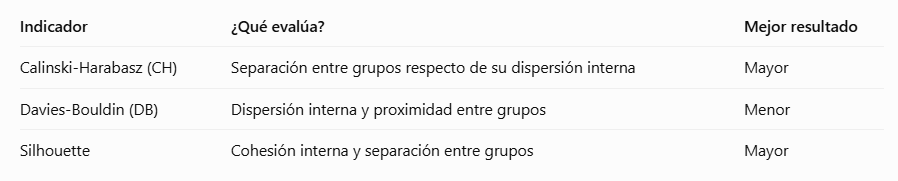

Silhouette, indicador complementario.

Entonces vamos a:
- Probamos distintas cantidades de clústeres, entre 2 y 10.
- Calculamos tres indicadores de calidad para cada solución.
- Obtenemos una tabla con 45 combinaciones (5 métodos × 9 cantidades de clústeres).

Resultados esperados de los indicadores:
- Valores elevados de Calinski-Harabasz.
- Valores bajos de Davies-Bouldin.
- Valores elevados de Silhouette.

No necesariamente los tres indicadores elegirán la misma cantidad de clústeres. Si hay diferencias, analizaremos cuál solución resulta más adecuada y fácil de interpretar.

In [94]:
from scipy.cluster.hierarchy import cut_tree
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score
)
import pandas as pd
import numpy as np

# Resultados de los indicadores
resultados_validacion = []

# Evaluar los cinco métodos jerárquicos
for nombre, modelo in modelos_jerarquicos.items():

    for k in range(2, 11):

        # Obtener etiquetas de los clústeres
        etiquetas = cut_tree(
            modelo, n_clusters=k
        ).ravel()

        # Verificar cantidad real de clústeres
        n_clusters = len(np.unique(etiquetas))

        # Evitar errores si no hay al menos 2 clústeres
        if n_clusters < 2:
            print(f"Se omite {nombre}, k={k}: solo {n_clusters} clúster.")
            continue

        # Calcular indicadores
        ch = calinski_harabasz_score(
            df_muestra, etiquetas
        )

        db = davies_bouldin_score(
            df_muestra, etiquetas
        )

        sil = silhouette_score(
            df_muestra, etiquetas
        )

        resultados_validacion.append({
            'METODO': nombre,
            'CLUSTERES': k,
            'CALINSKI_HARABASZ': ch,
            'DAVIES_BOULDIN': db,
            'SILHOUETTE': sil
        })

# Crear tabla comparativa
tabla_validacion = pd.DataFrame(resultados_validacion)

display(tabla_validacion.round(4))



Se omite Centroide, k=2: solo 1 clúster.
Se omite Centroide, k=3: solo 1 clúster.
Se omite Centroide, k=4: solo 1 clúster.
Se omite Centroide, k=5: solo 1 clúster.
Se omite Centroide, k=6: solo 1 clúster.
Se omite Centroide, k=7: solo 1 clúster.
Se omite Centroide, k=8: solo 1 clúster.
Se omite Centroide, k=9: solo 1 clúster.
Se omite Centroide, k=10: solo 1 clúster.


,METODO,CLUSTERES,CALINSKI_HARABASZ,DAVIES_BOULDIN,SILHOUETTE
0,Ward,2,185.5022,2.7155,0.1318
1,Ward,3,170.9793,2.2599,0.1194
2,Ward,4,147.8625,2.5276,0.0769
3,Ward,5,134.0943,2.3362,0.0794
4,Ward,6,123.8432,2.3108,0.0722
5,Ward,7,116.6915,2.2134,0.0656
6,Ward,8,111.4429,2.1350,0.0723
7,Ward,9,106.3372,2.2307,0.0749
8,Ward,10,101.8282,2.1349,0.0770
9,Vecino más cercano,2,7.6585,0.3481,0.5247


Corregimos el método Centroide que da error y comparamos el tamaño de los clústeres.

In [95]:
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import cut_tree
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score
)

# Función para obtener exactamente k clústeres
# incluso con el método Centroide
def obtener_clusters(modelo, k):
    n = modelo.shape[0] + 1

    # Identificadores iniciales de las observaciones
    grupos = {i: [i] for i in range(n)}

    # Reconstruir las fusiones hasta obtener k grupos
    for i, fila in enumerate(modelo[:n-k]):
        a, b = int(fila[0]), int(fila[1])
        grupos[n+i] = grupos.pop(a) + grupos.pop(b)

    etiquetas = np.empty(n, dtype=int)

    for numero, miembros in enumerate(grupos.values()):
        etiquetas[miembros] = numero

    return etiquetas

# Evaluar nuevamente los cinco métodos
resultados = []
tamanos = []

for nombre, modelo in modelos_jerarquicos.items():

    for k in range(2, 11):

        etiquetas = obtener_clusters(modelo, k)

        # Indicadores de validación
        ch = calinski_harabasz_score(df_muestra, etiquetas)
        db = davies_bouldin_score(df_muestra, etiquetas)
        sil = silhouette_score(df_muestra, etiquetas)

        # Tamaños de los grupos
        conteos = pd.Series(etiquetas).value_counts()

        resultados.append({
            'METODO': nombre,
            'CLUSTERES': k,
            'CALINSKI_HARABASZ': ch,
            'DAVIES_BOULDIN': db,
            'SILHOUETTE': sil
        })

        tamanos.append({
            'METODO': nombre,
            'CLUSTERES': k,
            'CLUSTER_MENOR': conteos.min(),
            'CLUSTER_MAYOR': conteos.max()
        })

# Tablas de resultados
tabla_validacion = pd.DataFrame(resultados)
tabla_tamanos = pd.DataFrame(tamanos)

# Mostrar comparación para 2, 3 y 4 clústeres
print("INDICADORES DE VALIDACIÓN")
display(
    tabla_validacion[
        tabla_validacion['CLUSTERES'].isin([2, 3, 4])
    ].round(4)
)

print("TAMAÑOS DE LOS CLÚSTERES")
display(
    tabla_tamanos[
        tabla_tamanos['CLUSTERES'].isin([2, 3, 4])
    ]
)


INDICADORES DE VALIDACIÓN


,METODO,CLUSTERES,CALINSKI_HARABASZ,DAVIES_BOULDIN,SILHOUETTE
0,Ward,2,185.5022,2.7155,0.1318
1,Ward,3,170.9793,2.2599,0.1194
2,Ward,4,147.8625,2.5276,0.0769
9,Vecino más cercano,2,7.6585,0.3481,0.5247
10,Vecino más cercano,3,6.7245,0.3835,0.4551
11,Vecino más cercano,4,6.3245,0.3930,0.4006
18,Vecino más lejano,2,92.4651,1.5950,0.2411
19,Vecino más lejano,3,77.5682,1.7032,0.1424
20,Vecino más lejano,4,59.1599,1.6178,0.1264
27,Promedio,2,7.6585,0.3481,0.5247


TAMAÑOS DE LOS CLÚSTERES


,METODO,CLUSTERES,CLUSTER_MENOR,CLUSTER_MAYOR
0,Ward,2,616,884
1,Ward,3,240,884
2,Ward,4,240,553
9,Vecino más cercano,2,1,1499
10,Vecino más cercano,3,1,1498
11,Vecino más cercano,4,1,1497
18,Vecino más lejano,2,64,1436
19,Vecino más lejano,3,56,1380
20,Vecino más lejano,4,11,1369
27,Promedio,2,1,1499


Se observa que los métodos con mejores indicadores no necesariamente generan grupos útiles para nuestro análisis.

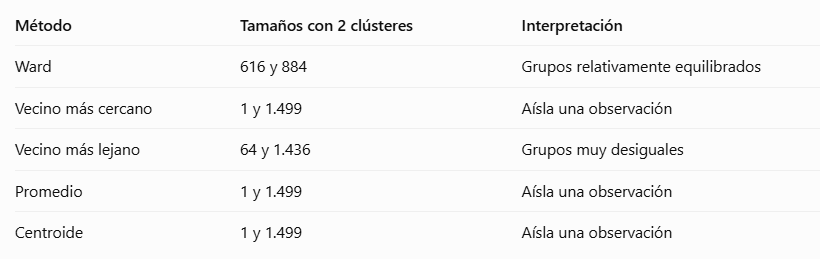

En conclusión:
- Ward: presenta el mayor índice Calinski-Harabasz (185,50) y forma grupos relativamente equilibrados.
- Single y Average: presentan mejores valores de Silhouette (0,5247), pero generan un grupo de 1.499 solicitantes y otro de una sola persona.
- Complete: produce grupos desiguales, aunque menos extremos.
- Centroide: también genera agrupamientos muy desequilibrados.

Esto confirma lo que sospechábamos al interpretar los dendrogramas: algunos métodos presentan un efecto de encadenamiento o aíslan observaciones.

La evaluación de los indicadores de validación y del tamaño de los conglomerados evidencia diferencias importantes entre los métodos jerárquicos.

Si bien los métodos de vecino más cercano y promedio presentan valores elevados del índice Silhouette y bajos de Davies-Bouldin, estos resultados se encuentran asociados a agrupamientos extremadamente desequilibrados, con un conglomerado de 1.499 observaciones y otro de una sola.

Por su parte, el método de Ward presenta el mayor índice Calinski-Harabasz y una distribución más equilibrada de las observaciones entre los conglomerados.

En consecuencia, Ward surge como el método más adecuado entre los evaluados para continuar el análisis, considerando conjuntamente los indicadores estadísticos y la distribución de los tamaños de los grupos. No obstante, sus valores bajos de Silhouette indican que la separación entre los conglomerados es limitada.

Entonces continuaremos el análisis con el el método de Ward que es el consideramos el más adecuado.

Tenemos resultados para 2 a 10 grupos, pero hasta ahora observamos que:
- Con 2 clústeres: 616 y 884 observaciones.
- Con 3 clústeres: el menor tiene 240 observaciones.
- Con 4 clústeres: el menor tiene 240 observaciones.

Comparamos específicamente las soluciones de Ward con 2, 3 y 4 clústeres, considerando los indicadores, los tamaños y las características financieras de cada grupo.

Así podremos elegir una cantidad de clústeres justificada antes de avanzar con su caracterización definitiva.

Comparación de soluciones de Ward para determinar el número óptimo de clústers.

In [96]:
from scipy.cluster.hierarchy import cut_tree
import pandas as pd

# Evaluar Ward con 2, 3 y 4 clústeres
resultados_ward = []

for k in [2, 3, 4]:

    # Obtener los grupos
    etiquetas = cut_tree(
        modelo_ward,
        n_clusters=k
    ).ravel()

    # Calcular tamaño de cada grupo
    tamanos = pd.Series(etiquetas).value_counts().sort_index()

    # Guardar resultados
    for cluster, cantidad in tamanos.items():
        resultados_ward.append({
            'NUMERO_CLUSTERES': k,
            'CLUSTER': cluster + 1,
            'OBSERVACIONES': cantidad,
            'PORCENTAJE': cantidad / len(df_muestra) * 100
        })

# Tabla de tamaños
tabla_ward = pd.DataFrame(resultados_ward)

display(tabla_ward.round(2))

# Indicadores de validación para Ward
print("INDICADORES DE VALIDACIÓN - WARD")

display(
    tabla_validacion[
        (tabla_validacion['METODO'] == 'Ward') &
        (tabla_validacion['CLUSTERES'].isin([2, 3, 4]))
    ].round(4)
)


,NUMERO_CLUSTERES,CLUSTER,OBSERVACIONES,PORCENTAJE
0,2,1,616,41.07
1,2,2,884,58.93
2,3,1,376,25.07
3,3,2,884,58.93
4,3,3,240,16.00
5,4,1,376,25.07
6,4,2,331,22.07
7,4,3,553,36.87
8,4,4,240,16.00


INDICADORES DE VALIDACIÓN - WARD


,METODO,CLUSTERES,CALINSKI_HARABASZ,DAVIES_BOULDIN,SILHOUETTE
0,Ward,2,185.5022,2.7155,0.1318
1,Ward,3,170.9793,2.2599,0.1194
2,Ward,4,147.8625,2.5276,0.0769


Se busca identificar una solución que presente:
- Grupos con tamaños razonables.
- Buena homogeneidad interna.
- Separación entre los conglomerados.
- Una cantidad de grupos que permita interpretar perfiles crediticios diferenciados.

Interpretación de los resultados:

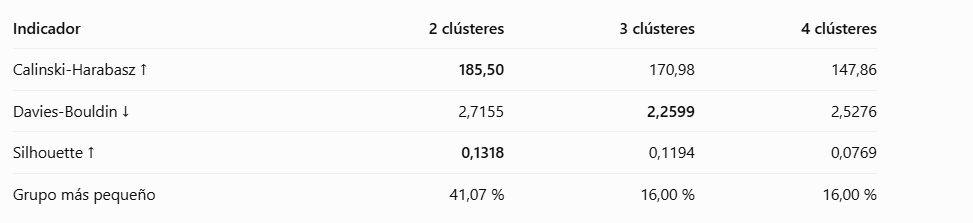

- 2 clústeres: presenta el mejor Calinski-Harabasz y Silhouette. Además, los grupos tienen tamaños relativamente equilibrados.
- 3 clústeres: presenta el mejor Davies-Bouldin, lo que sugiere una mejor relación entre dispersión interna y separación.
- 4 clústeres: no mejora ninguno de los tres indicadores respecto de las otras alternativas.

Descartamos la solución 4 y nos concentrarnos en las soluciones de 2 y 3 clústeres.

Hay una limitación importante: los valores de Silhouette son bajos en todas las soluciones, lo que indica que los grupos no están claramente separados.


Continuamos comparando los perfiles financieros.

Antes de elegir definitivamente entre 2 y 3 clústeres, vamos a analizar las características financieras de los grupos.

In [97]:
from scipy.cluster.hierarchy import cut_tree
import pandas as pd

# Comparar perfiles financieros de Ward con 2 y 3 clústeres
for k in [2, 3]:

    # Obtener etiquetas
    etiquetas = cut_tree(
        modelo_ward,
        n_clusters=k
    ).ravel() + 1

    # Recuperar observaciones originales de la muestra
    perfiles = df_tratada.loc[df_muestra.index].copy()

    # Incorporar clúster asignado
    perfiles['CLUSTER'] = etiquetas

    # Calcular medianas de las variables
    resumen = perfiles.groupby('CLUSTER').median()

    print(f"\nPERFILES FINANCIEROS - WARD CON {k} CLÚSTERES")
    display(resumen.round(2))



PERFILES FINANCIEROS - WARD CON 2 CLÚSTERES


,INGRESO_TOTAL,MONTO_CREDITO,CUOTA_CREDITO,ANTIGUEDAD_LABORAL,ANTIGUEDAD_REGISTRO,ANTIGUEDAD_DOCUMENTO,SCORE_EXTERNO_2,CANTIDAD_HIJOS,POBLACION_RELATIVA,EDAD_ANIOS
CLUSTER,,,,,,,,,,
1,180000.0,645158.25,30528.00,-2056.5,-4591.0,-1696.5,0.61,0.0,0.02,47.29
2,135000.0,450000.00,23946.75,-1473.0,-3920.5,-3873.0,0.55,1.0,0.02,35.77



PERFILES FINANCIEROS - WARD CON 3 CLÚSTERES


,INGRESO_TOTAL,MONTO_CREDITO,CUOTA_CREDITO,ANTIGUEDAD_LABORAL,ANTIGUEDAD_REGISTRO,ANTIGUEDAD_DOCUMENTO,SCORE_EXTERNO_2,CANTIDAD_HIJOS,POBLACION_RELATIVA,EDAD_ANIOS
CLUSTER,,,,,,,,,,
1,144000.0,504942.75,23814.00,-2063.0,-5651.0,-1466.5,0.56,0.0,0.02,48.77
2,135000.0,450000.00,23946.75,-1473.0,-3920.5,-3873.0,0.55,1.0,0.02,35.77
3,229500.0,1015830.00,43443.00,-2006.5,-3941.0,-2071.0,0.65,0.0,0.03,43.15


Solución con 2 clústers:

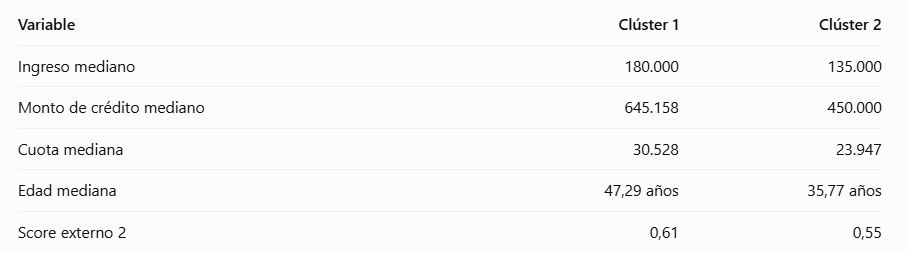

Interpretación: se identifican dos perfiles: solicitantes de mayor edad, ingresos y montos de crédito, frente a solicitantes más jóvenes, con ingresos y créditos menores.

Solcuión con 3 clústers:

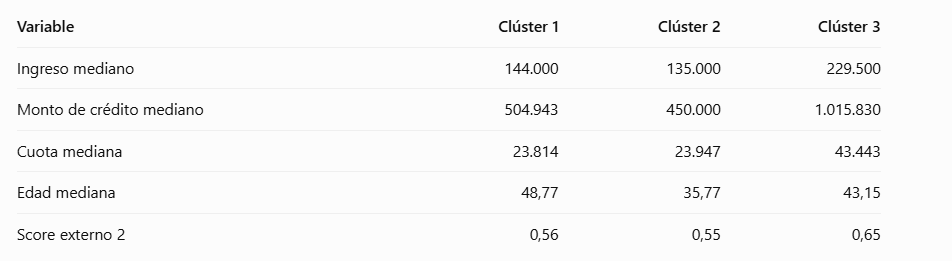

Interpretación: aparecen tres perfiles diferenciados:
- Clúster 1: solicitantes de mayor edad, con ingresos y créditos intermedios.
- Clúster 2: solicitantes jóvenes, con menores ingresos y créditos.
- Clúster 3: solicitantes con mayores ingresos, créditos y cuotas, de edad intermedia.

Me inclinaría por 3 clústeres, porque permite identificar tres perfiles financieros más interesantes e interpretables.

Sin embargo, hay una diferencia entre la interpretación económica y los indicadores estadísticos:
- 2 clústeres: mejores valores de Calinski-Harabasz y Silhouette.
- 3 clústeres: mejor Davies-Bouldin y mayor diferenciación de perfiles financieros.

Por eso, la elección de 3 grupos es defendible por su interpretación, pero no podemos afirmar que sea estadísticamente superior en todos los criterios.


Conclusión para el informe:

La comparación de las soluciones de Ward con dos y tres conglomerados muestra que ambas permiten identificar perfiles diferenciados de solicitantes de crédito.

La solución de dos conglomerados distingue principalmente entre solicitantes de mayor edad, ingresos y montos de crédito, y solicitantes más jóvenes con menores valores financieros.

Sin embargo, la solución de tres conglomerados permite una caracterización más detallada, diferenciando solicitantes jóvenes con menores ingresos y créditos, solicitantes de mayor edad con características financieras intermedias y solicitantes con mayores ingresos y montos de financiamiento.

Si bien la solución de dos conglomerados presenta mejores valores en algunos indicadores de validación, se propone seleccionar tres conglomerados, considerando su mayor capacidad descriptiva y el mejor resultado obtenido en el índice Davies-Bouldin.

Esta elección deberá interpretarse teniendo en cuenta que los valores de Silhouette indican una separación limitada entre los grupos.

### 4.7. Caracterización de los tres clústeres obtenidos mediante Ward

Ya conocemos sus características financieras principales. Ahora vamos a profundizar en su composición para poder interpretar y describir cada conglomerado.

Vamos a calcular el tamaño, las medias y las medianas de cada grupo. También construiremos un gráfico comparativo.

TAMAÑO DE LOS CLÚSTERES


,OBSERVACIONES,PORCENTAJE
CLUSTER,,
1,376,25.07
2,884,58.93
3,240,16.00



MEDIAS POR CLÚSTER


,INGRESO_TOTAL,MONTO_CREDITO,CUOTA_CREDITO,ANTIGUEDAD_LABORAL,ANTIGUEDAD_REGISTRO,ANTIGUEDAD_DOCUMENTO,SCORE_EXTERNO_2,CANTIDAD_HIJOS,POBLACION_RELATIVA,EDAD_ANIOS
CLUSTER,,,,,,,,,,
1,156721.49,546175.99,24679.97,-3236.07,-5536.89,-1633.84,0.51,0.19,0.02,48.72
2,158734.15,526950.41,25179.51,-1922.52,-4028.78,-3413.99,0.50,0.73,0.02,35.58
3,267114.38,1062713.32,44419.42,-2458.13,-4438.55,-2345.39,0.62,0.42,0.04,42.26



MEDIANAS POR CLÚSTER


,INGRESO_TOTAL,MONTO_CREDITO,CUOTA_CREDITO,ANTIGUEDAD_LABORAL,ANTIGUEDAD_REGISTRO,ANTIGUEDAD_DOCUMENTO,SCORE_EXTERNO_2,CANTIDAD_HIJOS,POBLACION_RELATIVA,EDAD_ANIOS
CLUSTER,,,,,,,,,,
1,144000.0,504942.75,23814.00,-2063.0,-5651.0,-1466.5,0.56,0.0,0.02,48.77
2,135000.0,450000.00,23946.75,-1473.0,-3920.5,-3873.0,0.55,1.0,0.02,35.77
3,229500.0,1015830.00,43443.00,-2006.5,-3941.0,-2071.0,0.65,0.0,0.03,43.15


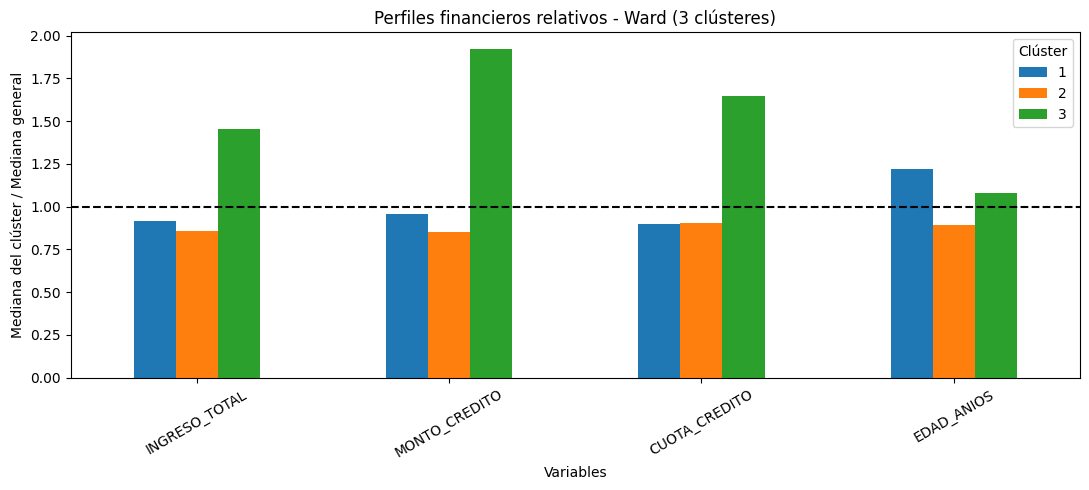

In [98]:
from scipy.cluster.hierarchy import cut_tree
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Obtener los 3 clústeres de Ward
etiquetas_ward = cut_tree(
    modelo_ward,
    n_clusters=3
).ravel() + 1

# 2. Recuperar las observaciones en unidades originales
df_perfiles_ward = df_tratada.loc[df_muestra.index].copy()

# Incorporar el clúster asignado
df_perfiles_ward['CLUSTER'] = etiquetas_ward

# 3. Calcular tamaño de cada clúster
tamanos = df_perfiles_ward['CLUSTER'].value_counts().sort_index()

print("TAMAÑO DE LOS CLÚSTERES")
display(pd.DataFrame({
    'OBSERVACIONES': tamanos,
    'PORCENTAJE': (tamanos / len(df_perfiles_ward) * 100).round(2)
}))

# 4. Caracterizar mediante medias y medianas
print("\nMEDIAS POR CLÚSTER")
display(
    df_perfiles_ward.groupby('CLUSTER')
    .mean().round(2)
)

print("\nMEDIANAS POR CLÚSTER")
display(
    df_perfiles_ward.groupby('CLUSTER')
    .median().round(2)
)

# 5. Comparación gráfica de variables financieras
variables_grafico = [
    'INGRESO_TOTAL',
    'MONTO_CREDITO',
    'CUOTA_CREDITO',
    'EDAD_ANIOS'
]

medianas = df_perfiles_ward.groupby('CLUSTER')[
    variables_grafico
].median()

# Normalizar respecto de la mediana general
mediana_general = df_perfiles_ward[
    variables_grafico
].median()

medianas_relativas = medianas.div(mediana_general)

# Gráfico
medianas_relativas.T.plot(
    kind='bar',
    figsize=(11, 5)
)

plt.title('Perfiles financieros relativos - Ward (3 clústeres)')
plt.ylabel('Mediana del clúster / Mediana general')
plt.xlabel('Variables')
plt.axhline(1, linestyle='--', color='black')
plt.xticks(rotation=30)
plt.legend(title='Clúster')
plt.tight_layout()
plt.show()


Tamaño de los conglomerados:
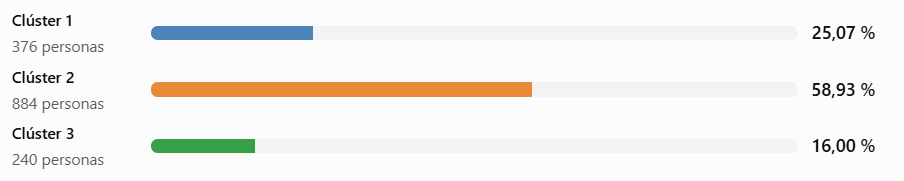

Caracterización financiera:

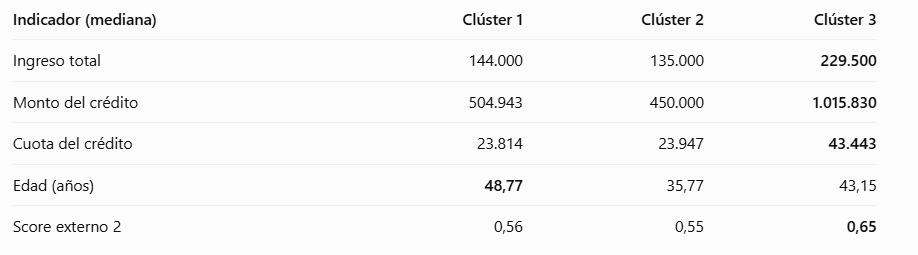

Clúster 1 — Solicitantes de mayor edad: presenta la edad mediana más elevada, ingresos intermedios y montos de crédito moderados.

Clúster 2 — Solicitantes jóvenes: es el grupo mayoritario. Presenta menor edad, menores ingresos y créditos relativamente bajos.

Clúster 3 — Solicitantes de mayor capacidad económica: presenta los mayores ingresos, montos de crédito y cuotas. Es el grupo más pequeño.

El gráfico confirma visualmente estas diferencias. El clúster 3 destaca por sus mayores ingresos y financiamiento, mientras que el clúster 1 se diferencia principalmente por la edad.

Un detalle interesante: el clúster 3 tiene una mediana de crédito casi el doble de la mediana general, lo que evidencia un perfil financiero claramente distinto.

Conclusión para el informe:

La aplicación del método jerárquico de Ward permitió identificar tres conglomerados de solicitantes de crédito con características diferenciadas.

El primer conglomerado, integrado por el 25,07 % de la muestra, se caracteriza por solicitantes de mayor edad y condiciones financieras intermedias.

El segundo conglomerado, que representa el 58,93 % de las observaciones, agrupa principalmente a solicitantes más jóvenes, con menores ingresos y montos de crédito.

Finalmente, el tercer conglomerado, que concentra el 16 % de la muestra, presenta los mayores niveles de ingresos, montos de crédito y cuotas, identificando un perfil de mayor capacidad económica relativa.

Los resultados muestran que las variables financieras y sociodemográficas permiten identificar perfiles diferenciados, aunque los indicadores de validación obtenidos anteriormente sugieren una separación limitada entre los grupos.

## 5. Método no jerárquico K-means

La idea es aplicar K-means inicialmente con 3 clústeres, para comparar los perfiles obtenidos con Ward. Después evaluaremos si esa cantidad también es adecuada para K-means mediante indicadores de validación.

En esta etapa podremos utilizar las 219.655 observaciones estandarizadas, en lugar de limitarnos a la muestra de 1.500 solicitantes. Esto nos permitirá comprobar si los perfiles identificados con Ward también aparecen al analizar una cantidad mucho mayor de solicitudes de crédito.



### 5.1. Aplicación de K-means con 3 clústeres

A diferencia de Ward, K-means requiere definir previamente la cantidad de grupos.

El algoritmo:
- Establece 3 centroides iniciales.
- Asigna cada solicitante al centroide más cercano.
- Recalcula los centroides según las observaciones asignadas.
- Repite el procedimiento hasta alcanzar la convergencia.

Su objetivo es minimizar la suma de cuadrados de las distancias dentro de los clústeres.

Vamos a utilizar las 219.655 observaciones estandarizadas.

In [99]:
from sklearn.cluster import KMeans
import pandas as pd

# PASO 5.1. Aplicación de K-means con 3 clústeres

# 1. Crear el modelo
modelo_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# 2. Aplicar K-means a los datos estandarizados
etiquetas_kmeans = modelo_kmeans.fit_predict(
    df_estandarizada
)

# 3. Crear base con los clústeres asignados
df_kmeans = df_tratada.copy()

df_kmeans['CLUSTER'] = etiquetas_kmeans + 1

# 4. Calcular tamaño de cada clúster
tamanos_kmeans = (
    df_kmeans['CLUSTER']
    .value_counts()
    .sort_index()
)

# 5. Mostrar resultados
print("OBSERVACIONES:", len(df_kmeans))
print("NÚMERO DE CLÚSTERES:", modelo_kmeans.n_clusters)
print("INERCIA:", round(modelo_kmeans.inertia_, 2))

display(pd.DataFrame({
    'OBSERVACIONES': tamanos_kmeans,
    'PORCENTAJE': (
        tamanos_kmeans / len(df_kmeans) * 100
    ).round(2)
}))


OBSERVACIONES: 219655
NÚMERO DE CLÚSTERES: 3
INERCIA: 1691018.61


,OBSERVACIONES,PORCENTAJE
CLUSTER,,
1,51042,23.24
2,104391,47.52
3,64222,29.24


- n_clusters=3: elegimos inicialmente tres grupos para compararlos con Ward.
- random_state=42: permite reproducir los resultados.
- n_init=10: ejecuta K-means con diez inicializaciones y conserva la solución de menor inercia.
- fit_predict(): calcula los clústeres y asigna cada observación a uno de ellos.
- inertia_: representa la suma de cuadrados de las distancias de las observaciones a sus respectivos centroides.

Conclusiones de interpretar los tamaños de los grupos, sus centroides y características financieras para compararlos con Ward.

- Los tres clústeres tienen tamaños considerables.
- El clúster 2 concentra la mayor cantidad de solicitantes.
- No observamos grupos extremadamente pequeños, como ocurría con algunos métodos jerárquicos.

La inercia de 1.691.018,61 representa la variabilidad interna total de los clústeres. Todavía no podemos determinar si es elevada o baja sin compararla con otras soluciones.

### 5.2. Caracterización de los clústeres de K-means

In [100]:
# Caracterización de K-means

# 1. Calcular medianas por clúster
medianas_kmeans = (
    df_kmeans.groupby('CLUSTER')
    .median()
)

# 2. Calcular medias por clúster
medias_kmeans = (
    df_kmeans.groupby('CLUSTER')
    .mean()
)

# 3. Mostrar resultados
print("MEDIANAS POR CLÚSTER")
display(medianas_kmeans.round(2))

print("\nMEDIAS POR CLÚSTER")
display(medias_kmeans.round(2))


MEDIANAS POR CLÚSTER


,INGRESO_TOTAL,MONTO_CREDITO,CUOTA_CREDITO,ANTIGUEDAD_LABORAL,ANTIGUEDAD_REGISTRO,ANTIGUEDAD_DOCUMENTO,SCORE_EXTERNO_2,CANTIDAD_HIJOS,POBLACION_RELATIVA,EDAD_ANIOS
CLUSTER,,,,,,,,,,
1,225000.0,1078200.0,43312.5,-1836.0,-3878.0,-3212.0,0.63,0.0,0.02,39.90
2,135000.0,376920.0,21663.0,-1317.0,-3387.0,-3447.0,0.52,1.0,0.02,34.02
3,135000.0,500211.0,23755.5,-2560.0,-6421.0,-1807.0,0.58,0.0,0.02,48.60



MEDIAS POR CLÚSTER


,INGRESO_TOTAL,MONTO_CREDITO,CUOTA_CREDITO,ANTIGUEDAD_LABORAL,ANTIGUEDAD_REGISTRO,ANTIGUEDAD_DOCUMENTO,SCORE_EXTERNO_2,CANTIDAD_HIJOS,POBLACION_RELATIVA,EDAD_ANIOS
CLUSTER,,,,,,,,,,
1,266446.02,1102427.26,45698.74,-2338.00,-4169.44,-3002.69,0.59,0.56,0.03,39.97
2,146715.47,426653.01,21816.52,-1699.85,-3600.35,-3223.07,0.47,0.79,0.02,34.37
3,150560.61,532278.51,23977.98,-3376.27,-6186.93,-1957.46,0.53,0.17,0.02,48.21


Calculamos las medianas y medias de las 10 variables para identificar qué características diferencian a los tres grupos.

Los números de los clústeres son etiquetas arbitrarias. El clúster 1 de K-means no necesariamente corresponde al clúster 1 de Ward.

Los resultados muestran que K-means también identificó tres perfiles financieros diferenciados, bastante similares a los obtenidos mediante Ward.

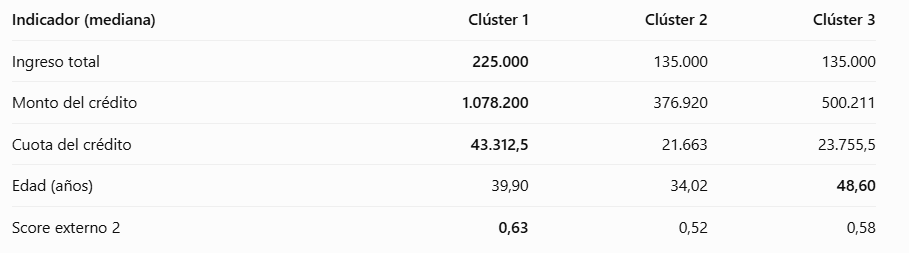

El primer clúster (23,24 %) se caracteriza por presentar los mayores ingresos, montos de crédito y cuotas, representando solicitantes con mayor capacidad económica relativa.

El segundo clúster (47,52 %) agrupa principalmente a solicitantes jóvenes, con menores ingresos y niveles de financiamiento.

El tercer clúster (29,24 %) se caracteriza por solicitantes de mayor edad, con ingresos relativamente bajos y montos de crédito intermedios.


Comparación con Ward:

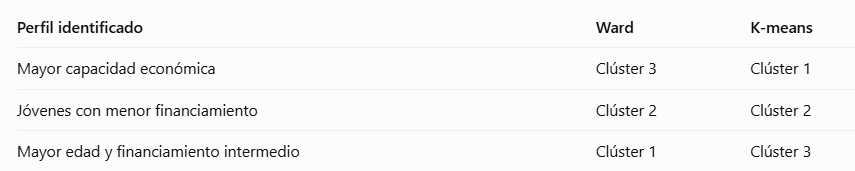


Ambos métodos identifican perfiles conceptualmente similares, aunque con diferentes proporciones de solicitantes.

Esto es interesante porque Ward se aplicó sobre 1.500 observaciones, mientras que K-means utilizó 219.655.

Sin embargo, todavía no podemos afirmar que los agrupamientos sean equivalentes: debemos considerar que se aplicaron sobre conjuntos de distinto tamaño.

### 5.3. Determinación del número óptimo de clústeres para K-means.

El siguiente paso es validar la solución de K-means con tres clústeres.

Cmparamos soluciones con 2, 3, 4 y 5 clústeres, utilizando Calinski-Harabasz y Davies-Bouldin, que ya aplicamos en el análisis jerárquico.

,CLUSTERES,CALINSKI_HARABASZ,DAVIES_BOULDIN,INERCIA
0,2,35853.33,2.31,1888326.11
1,3,32832.69,2.08,1691018.61
2,4,28033.51,2.16,1588386.58
3,5,25559.58,2.07,1498882.60


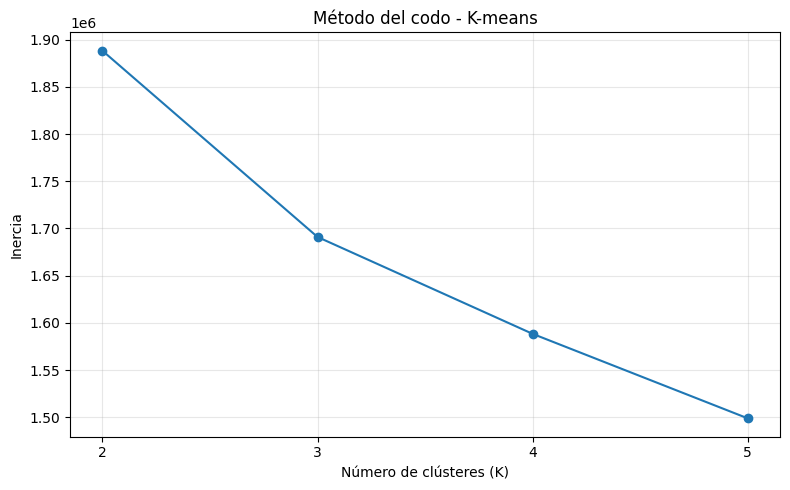

In [101]:
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score
import pandas as pd
import matplotlib.pyplot as plt

# PASO 5.3. Evaluación del número óptimo de clústeres

resultados_k = []

# Evaluar soluciones de 2 a 5 clústeres
for k in range(2, 6):

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(df_estandarizada)

    # Calcular indicadores
    ch = calinski_harabasz_score(
        df_estandarizada, etiquetas
    )

    db = davies_bouldin_score(
        df_estandarizada, etiquetas
    )

    resultados_k.append({
        'CLUSTERES': k,
        'CALINSKI_HARABASZ': ch,
        'DAVIES_BOULDIN': db,
        'INERCIA': modelo.inertia_
    })

# Crear tabla comparativa
tabla_kmeans = pd.DataFrame(resultados_k)

display(tabla_kmeans.round(2))

# Gráfico del método del codo
plt.figure(figsize=(8, 5))

plt.plot(
    tabla_kmeans['CLUSTERES'],
    tabla_kmeans['INERCIA'],
    marker='o'
)

plt.title('Método del codo - K-means')
plt.xlabel('Número de clústeres (K)')
plt.ylabel('Inercia')
plt.xticks(range(2, 6))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- Ejecutamos K-means cuatro veces, con K = 2, 3, 4 y 5.
- Calculamos Calinski-Harabasz y Davies-Bouldin para cada solución.
- Registramos la inercia de cada modelo.
- Construimos el gráfico del codo para analizar cómo disminuye la variabilidad interna al aumentar K.

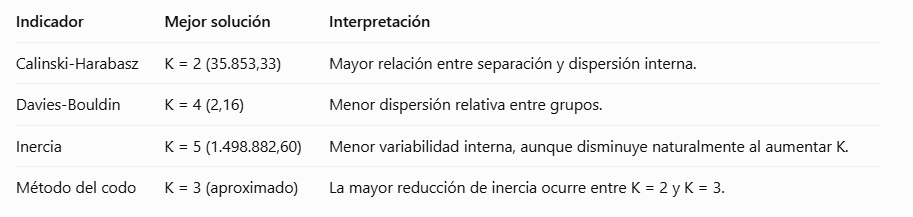

La inercia disminuye considerablemente de 2 a 3 clústeres. Después continúa disminuyendo, pero de manera menos pronunciada.

Esto sugiere un posible codo en K = 3, aunque no es muy marcado.

Hay una aclaración: los valores de Davies-Bouldin para K = 3, 4 y 5 son bastante similares (2,08; 2,16 y 2,07, respectivamente). Por lo tanto, K = 5 tiene en realidad el mejor Davies-Bouldin, aunque por una diferencia muy pequeña respecto de K = 3.

Mantendría K = 3 para nuestro análisis, por tres motivos:
- El gráfico del codo sugiere una mejora importante hasta K = 3.
- Davies-Bouldin presenta un valor competitivo (2,08).
- Los tres grupos obtenidos tienen perfiles financieros interpretables y similares conceptualmente a los identificados mediante Ward.

Sin embargo, Calinski-Harabasz favorece K = 2 y Davies-Bouldin favorece ligeramente K = 5.

Ya tenemos Ward con 3 clústeres y K-means con 3 clústeres.

Ahora corresponde realizar la comparación final entre ambos métodos y analizar si los grupos obtenidos son consistentes.

Utilizaremos una tabla comparativa de perfiles financieros y, si queremos una evaluación más rigurosa, calcular el índice de Rand ajustado (ARI) sobre las mismas 1.500 observaciones.

Esto último es importante porque Ward se aplicó sobre una muestra y K-means sobre la base completa. El ARI permitiría comparar directamente las asignaciones de ambos métodos sobre los mismos solicitantes, sin depender de que los números de los clústeres coincidan.

## 6. Comparación entre Ward y K-means

Vamos a comprobar si ambos métodos agrupan de manera similar a los solicitantes de crédito.

Como Ward se aplicó sobre 1.500 observaciones y K-means sobre 219.655, utilizaremos los mismos 1.500 solicitantes para realizar una comparación válida.

### 6.1. Comparación mediante el índice de Rand ajustado (ARI)

El ARI mide el grado de coincidencia entre dos agrupamientos, teniendo en cuenta las coincidencias que podrían producirse por azar.

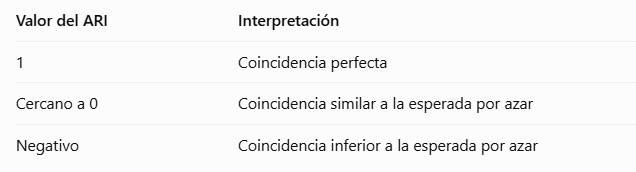


Calculamos el ARI para evaluar el grado de coincidencia.

Construimos una tabla cruzada que muestra cómo se distribuyen los solicitantes entre ambos métodos. Interpretaremos si Ward y K-means identifican agrupamientos similares.

In [102]:
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import cut_tree
import pandas as pd

# PASO 6.1. Comparación Ward vs. K-means

# 1. Recuperar los 3 clústeres de Ward
etiquetas_ward = cut_tree(
    modelo_ward,
    n_clusters=3
).ravel()

# 2. Recuperar los clústeres de K-means
# para las mismas 1.500 observaciones
etiquetas_kmeans_muestra = df_kmeans.loc[
    df_muestra.index, 'CLUSTER'
].to_numpy()

# 3. Calcular índice de Rand ajustado
ari = adjusted_rand_score(
    etiquetas_ward,
    etiquetas_kmeans_muestra
)

print("Índice de Rand ajustado (ARI):", round(ari, 4))

# 4. Tabla de coincidencias entre métodos
tabla_comparacion = pd.crosstab(
    etiquetas_ward + 1,
    etiquetas_kmeans_muestra,
    rownames=['WARD'],
    colnames=['K-MEANS']
)

display(tabla_comparacion)


Índice de Rand ajustado (ARI): 0.4982


K-MEANS,1,2,3
WARD,,,
1,26,13,337
2,146,668,70
3,182,7,51


Ward y K-means presentan una concordancia moderada (ARI = 0,4982), lo que respalda parcialmente la consistencia de los perfiles financieros identificados mediante ambas técnicas.

Indica una concordancia moderada entre ambos métodos.
- Los métodos identifican agrupamientos similares.
- Existen diferencias en la asignación de algunos solicitantes.
- No podemos afirmar que ambos métodos produzcan exactamente los mismos clústeres.

### 6.2. Comprobación de estabilidad de K-means

Queremos saber si K-means sigue identificando grupos similares cuando cambiamos la muestra de solicitantes.

Para eso, entrenaremos K-means con cinco muestras aleatorias y compararemos sus resultados con nuestro modelo original mediante el índice ARI.

Interpretación de los resultados:

- ARI cercano a 1: los agrupamientos son muy similares; indica mayor estabilidad.
- ARI cercano a 0: los agrupamientos cambian considerablemente.
- Valores intermedios: indican estabilidad parcial.

In [103]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import pandas as pd

# PASO 6.2. Evaluación de estabilidad de K-means

resultados_estabilidad = []

# Repetir el análisis con 5 muestras aleatorias
for semilla in range(5):

    # Seleccionar 10.000 observaciones para entrenar
    muestra = df_estandarizada.sample(
        n=10000,
        random_state=semilla
    )

    # Entrenar K-means con 3 clústeres
    modelo = KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    )

    modelo.fit(muestra)

    # Predecir los grupos de los mismos 1.500 solicitantes
    etiquetas_nuevas = modelo.predict(df_muestra)

    # Grupos asignados por el modelo original
    etiquetas_originales = modelo_kmeans.predict(df_muestra)

    # Comparar agrupamientos
    ari = adjusted_rand_score(
        etiquetas_originales,
        etiquetas_nuevas
    )

    resultados_estabilidad.append({
        'MUESTRA': semilla + 1,
        'ARI': ari
    })

# Mostrar resultados
tabla_estabilidad = pd.DataFrame(resultados_estabilidad)

display(tabla_estabilidad.round(4))

print(
    "ARI promedio:",
    round(tabla_estabilidad['ARI'].mean(), 4)
)

print(
    "ARI mínimo:",
    round(tabla_estabilidad['ARI'].min(), 4)
)


,MUESTRA,ARI
0,1,0.9717
1,2,0.9598
2,3,0.9660
3,4,0.9685
4,5,0.9636


ARI promedio: 0.9659
ARI mínimo: 0.9598


- ARI promedio: 0,9659.
- ARI mínimo: 0,9598.
- ARI máximo: 0,9717.

Los resultados indican una estabilidad muy alta de K-means. Al entrenar el modelo con cinco muestras diferentes, los agrupamientos obtenidos fueron muy similares a los del modelo original.

Esto respalda la robustez de nuestra solución de tres clústeres frente a cambios en la muestra utilizada.

En conclusión, la comprobación fue satisfactoria. Aunque anteriormente observamos una separación limitada entre los clústeres, ahora sabemos que la solución es bastante estable.

Son dos aspectos diferentes: los grupos pueden no estar perfectamente separados, pero aun así mantenerse estables.

## 7. Conclusiones del análisis

El presente trabajo tuvo como objetivo identificar y caracterizar perfiles de solicitantes de crédito mediante la aplicación de técnicas de análisis de conglomerados, utilizando la base de datos *Home Credit Default Risk*.

Luego del análisis exploratorio y la preparación de los datos, se trabajó con **219.655 observaciones y 10 variables métricas**, correspondientes a solicitantes de crédito de entre 25 y 55 años.

Se aplicaron cinco métodos jerárquicos: Ward, vecino más cercano, vecino más lejano, vinculación promedio y centroide. A partir de la comparación de dendrogramas, correlaciones cofenéticas e indicadores de validación, se seleccionó el método de Ward, considerando principalmente la conformación de grupos de tamaños razonables y su interpretación financiera.

Para este método se eligió una solución de tres conglomerados, que permitió identificar perfiles diferenciados según edad, ingresos y características del financiamiento.

Posteriormente, se aplicó el método no jerárquico K-means sobre las 219.655 observaciones, seleccionando también una solución de tres conglomerados a partir de los indicadores de validación y su interpretación económica.

Ambos métodos permitieron identificar tres perfiles principales:

- **Solicitantes jóvenes con menores ingresos y montos de crédito.**
- **Solicitantes de mayor edad con niveles de financiamiento intermedios.**
- **Solicitantes con mayores ingresos, montos de crédito y cuotas.**

La comparación entre ambos procedimientos mediante el índice de Rand ajustado (ARI = 0,4982) evidenció una concordancia moderada, lo que indica que, si bien existen diferencias en la asignación individual de observaciones, ambos métodos identifican estructuras de agrupamiento parcialmente similares.

En conclusión, las técnicas de análisis de conglomerados permitieron segmentar a los solicitantes según sus características económicas, financieras y sociodemográficas, proporcionando información útil para comprender la heterogeneidad de los perfiles crediticios.

No obstante, los indicadores de validación evidenciaron una separación limitada entre algunos grupos, por lo que los resultados deben interpretarse como una segmentación exploratoria y no como categorías crediticias definitivas.